# 05 · 苍穹外卖：店铺营业状态设置

来源：本地 `讲义.rar / 讲义/day05/苍穹外卖-day05.md` 与 `PPT.rar / PPT/day05-店铺营业状态设置.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章先学习Redis的安装、五种常用数据类型与命令，再通过Spring Data Redis读写数据，最后实现管理端设置状态、管理端查询状态、用户端查询状态三个接口。保留讲义原代码、表格和配图，按49页PPT核对内容，补充说明与勘误独立标注。配图已内嵌，可离线阅读。

跟练需要已有sky-server工程、员工登录与管理端鉴权、Nginx管理页面，以及可连接的Redis服务。Java示例和命令用于阅读与工程跟练，Notebook中的Markdown单元无需运行。

> **重点勘误。** 原代码在SHOP_STATUS不存在时，读取null后用 `status == 1` 比较，会因自动拆箱发生空指针。原RedisTemplate只设置key序列化，value仍使用默认JDK序列化；不能直接用命令行 `SET SHOP_STATUS 1` 初始化后，期待原Java代码正常反序列化。后面分别说明兼容课程实现的修正方式，以及改用纯字符串存储时的迁移要求。


## 本章路线、接口与数据流（补充）

| 顺序 | 学习内容 | 完成标准 |
| --- | --- | --- |
| 1 | Redis入门 | 区分服务端和客户端，能连接正确地址、端口与数据库 |
| 2 | 常用类型 | 知道string、hash、list、set、zset的选择依据 |
| 3 | 命令跟练 | 观察返回值、列表顺序、集合去重、分数排序和过期时间 |
| 4 | Java访问Redis | 配置连接、理解RedisTemplate及序列化 |
| 5 | 营业状态 | 两端读取同一个key，只有管理端提供写接口 |

### 三个营业状态接口

| 功能 | 方法与后端路径 | 参数及结果 |
| --- | --- | --- |
| 管理端设置状态 | `PUT /admin/shop/{status}` | Path：status，1营业、0打烊；Result成功或错误 |
| 管理端查询 | `GET /admin/shop/status` | 无业务参数；Result.data为状态整数 |
| 用户端查询 | `GET /user/shop/status` | 无业务参数；读取同一个营业状态 |

管理页面通过Nginx的 `/api/...` 入口转发到 `/admin/...`；接口文档测试使用实际后端路径。受保护的管理端接口需要员工登录token；用户端接口的登录策略以实际用户端拦截器配置为准，不能拿管理员token约定直接套用。

### 状态数据流

```text
管理端选择营业/打烊
    → PUT /admin/shop/{status}
    → RedisTemplate.opsForValue().set("SHOP_STATUS", status)
    → Redis中保存该状态

管理端GET /admin/shop/status ─┐
                           ├→ 从同一个Redis数据库读取SHOP_STATUS
用户端GET /user/shop/status ─┘  → Result<Integer>返回1或0
```

课程示例是单店铺，使用固定key `SHOP_STATUS`，没有设计多店铺id。以后扩展多店铺时可以使用 `shop:{shopId}:status`，并同步增加权限与接口参数规则。

### 跟练前检查

1. Redis服务已启动；Java配置与客户端连接的host、port、password一致。
2. 原讲义Java连接使用database=10，命令行默认连接db0；查看课程数据先执行 `SELECT 10`。
3. 修改营业状态前取得有效员工token；普通Redis练习使用独立的 `note:day05:` 前缀。
4. 明确当前value序列化方案，再选择Java或命令行初始化状态，避免混写。


## 课程内容

> **PPT对照：** 第1—3页。

- Redis入门
- Redis数据类型
- Redis常用命令
- 在Java中操作Redis
- 店铺营业状态设置


功能实现：**营业状态设置**

**效果图：**

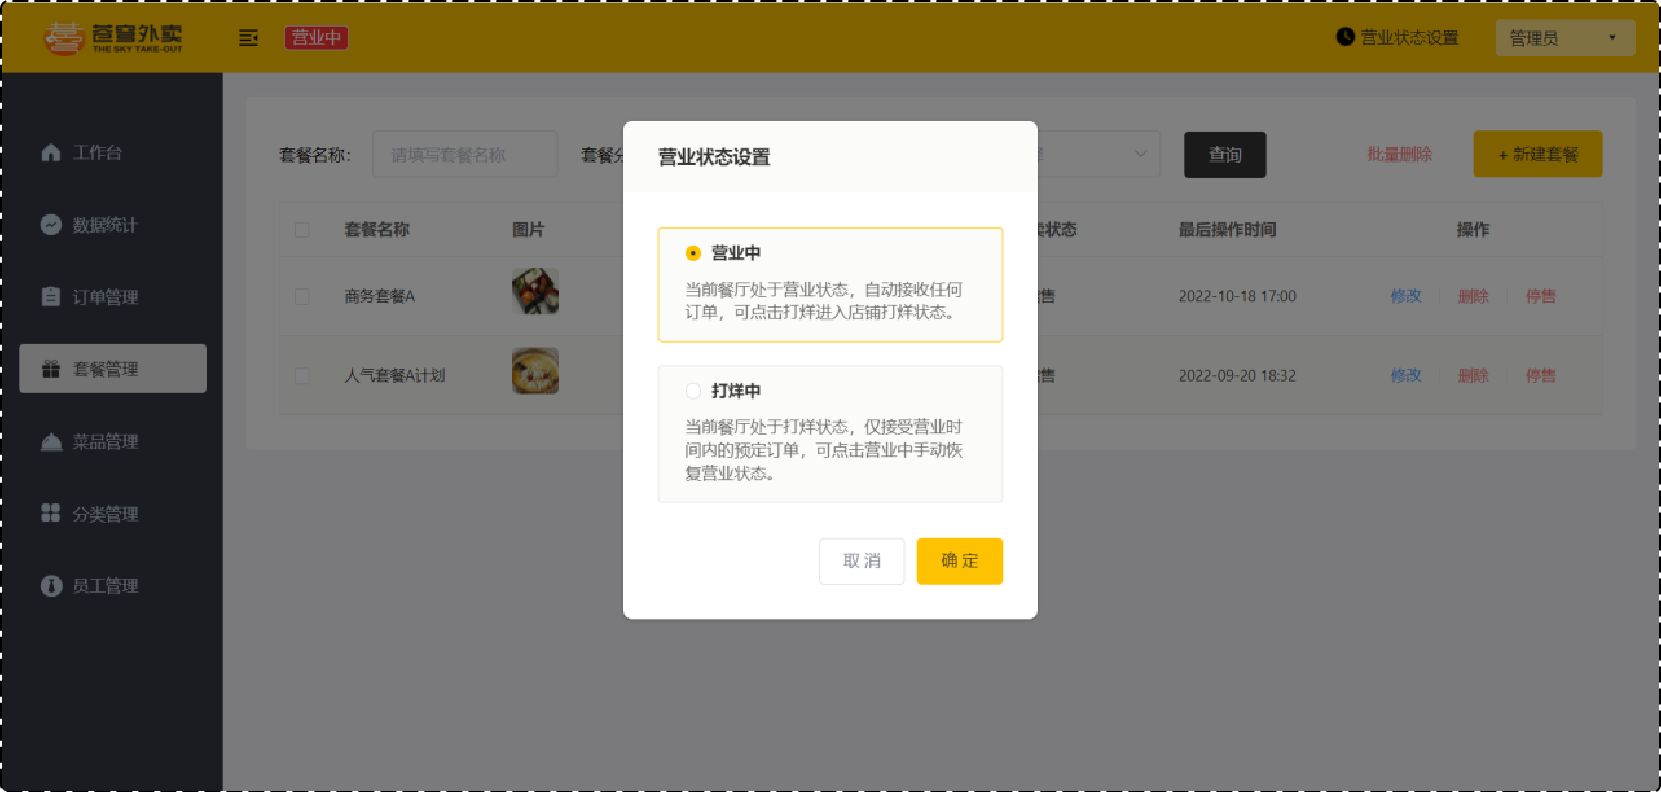 

选择**营业中**，客户可在小程序端下单：

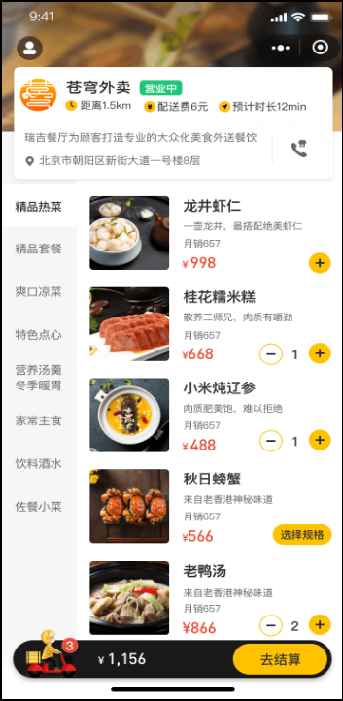 

选择**打烊中**，客户无法在小程序端下单：

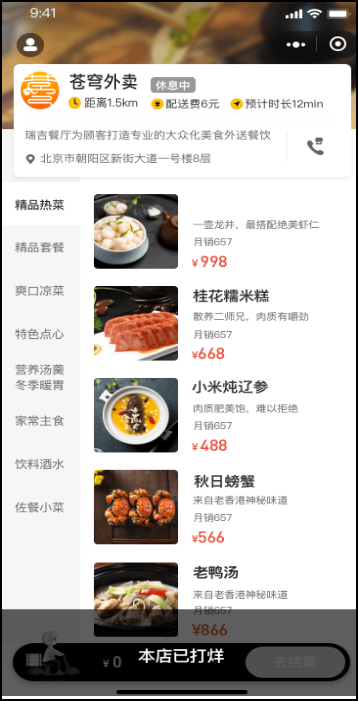


## 1. Redis入门

> **PPT对照：** 第4—13页。


### 1.1 Redis简介

> **PPT对照：** 第5页。

Redis是一个基于**内存**的key-value结构数据库。Redis 是互联网技术领域使用最为广泛的**存储中间件**。

**官网：**https://redis.io
**中文网：**https://www.redis.net.cn/

**key-value结构存储：**

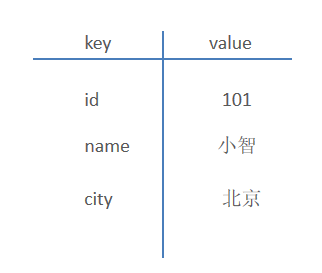 

**主要特点：**

- 基于内存存储，读写性能高  
- 适合存储热点数据（热点商品、资讯、新闻）
- 企业应用广泛

Redis是用C语言开发的一个开源的高性能键值对(key-value)数据库，官方提供的数据是可以达到100000+的QPS（每秒内查询次数）。它存储的value类型比较丰富，也被称为结构化的NoSql数据库。

NoSql（Not Only SQL），不仅仅是SQL，泛指**非关系型数据库**。NoSql数据库并不是要取代关系型数据库，而是关系型数据库的补充。

**关系型数据库(RDBMS)：**

- Mysql
- Oracle
- DB2
- SQLServer

**非关系型数据库(NoSql)：**

- Redis
- Mongo db
- MemCached


### Redis与MySQL如何分工（补充）

MySQL适合保存员工、分类、菜品、订单等业务记录及其关系；Redis适合快速读取热点数据、短期验证码，以及本章的店铺状态。Redis不是只能做缓存，也不等于所有数据必然在重启后丢失，它有RDB、AOF等持久化方式。

原文“100000+ QPS”是介绍性性能数字，不能当成你当前电脑、网络和所有命令的性能保证。实际速度受命令复杂度、数据量、连接方式、持久化配置和硬件影响。

NoSQL是数据库类别，不表示不能查询，也不表示要替代关系型数据库。选择Redis保存营业状态是课程的简化设计；真实项目也可以把店铺配置持久化到数据库，并用Redis加速查询。


### 1.2 Redis下载与安装

> **PPT对照：** 第7—8页。

#### 1.2.1 Redis下载

Redis安装包分为windows版和Linux版：

- Windows版下载地址：https://github.com/microsoftarchive/redis/releases
- Linux版下载地址： https://download.redis.io/releases/ 

资料中已提供好的安装包：

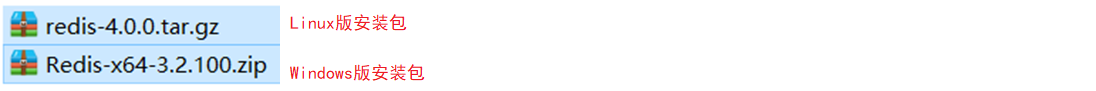 


#### 1.2.2 Redis安装

**1）在Windows中安装Redis(项目中使用)**

Redis的Windows版属于绿色软件，直接解压即可使用，解压后目录结构如下：

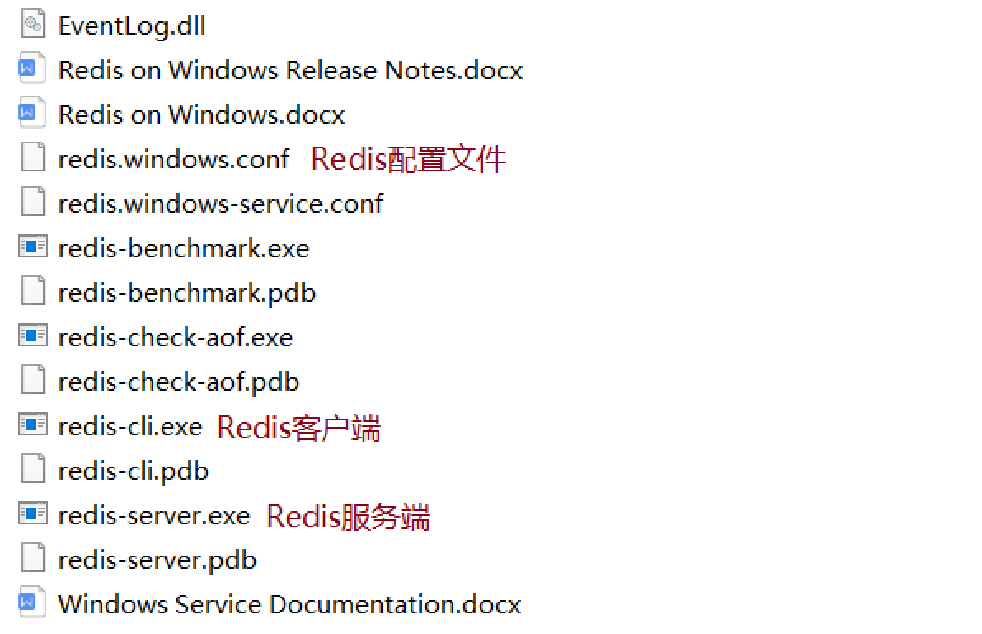 


**2）在Linux中安装Redis(简单了解)**

在Linux系统安装Redis步骤：

1. 将Redis安装包上传到Linux
2. 解压安装包，命令：tar -zxvf redis-4.0.0.tar.gz -C /usr/local
3. 安装Redis的依赖环境gcc，命令：yum install gcc-c++
4. 进入/usr/local/redis-4.0.0，进行编译，命令：make
5. 进入redis的src目录进行安装，命令：make install

安装后重点文件说明：

- /usr/local/redis-4.0.0/src/redis-server：Redis服务启动脚本
- /usr/local/redis-4.0.0/src/redis-cli：Redis客户端脚本
- /usr/local/redis-4.0.0/redis.conf：Redis配置文件


### 课程安装资料的版本背景（补充与勘误）

讲义使用MicrosoftArchive提供的旧Windows移植版，以及Redis 4.0.0的Linux源码示例。MicrosoftArchive仓库已归档，该Windows包不是当前Redis官方持续维护的原生Windows发行版。

已有课程安装包可用于本地跟练，命令与后续Java连接按当前安装版本验证。新环境可选择WSL中的Linux版本或容器运行，不必为了记住命令重复安装多个实例。Linux示例中的tar路径、yum包管理器和编译依赖与实际发行版有关，不能直接照搬到所有系统。

本笔记保留历史资料链接和命令，便于对照课程；安装与版本升级应以官方文档和实际环境为准。这里整理笔记，不会替你安装或更换正在使用的Redis。


### 1.3 Redis服务启动与停止

> **PPT对照：** 第10—13页。

以window版Redis进行演示：

#### 1.3.1 服务启动命令

**redis-server.exe redis.windows.conf**

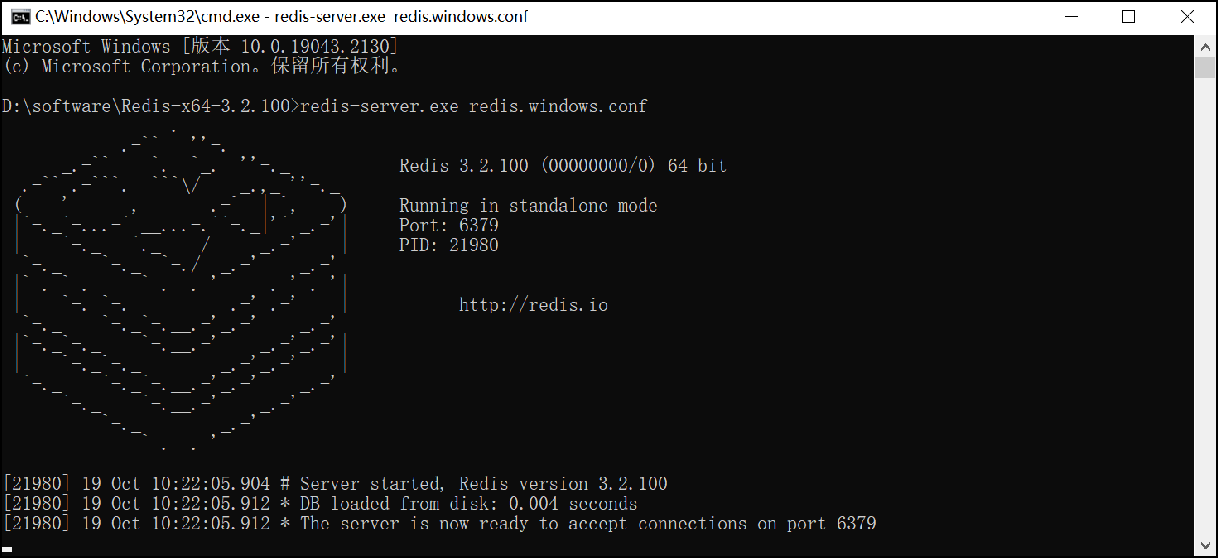 

Redis服务默认端口号为 **6379** ，通过快捷键**Ctrl + C** 即可停止Redis服务

当Redis服务启动成功后，可通过客户端进行连接。


#### 1.3.2 客户端连接命令

**redis-cli.exe**

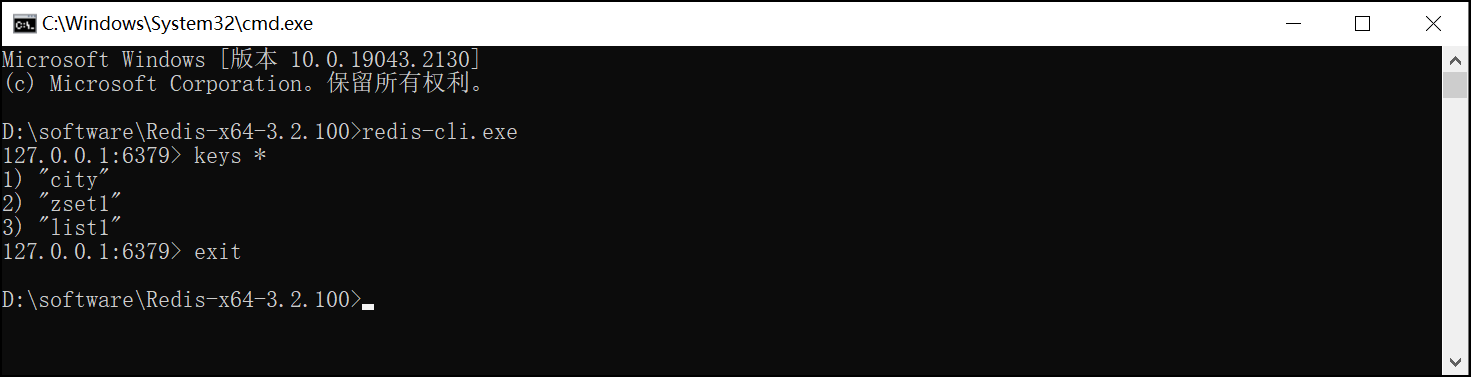 

通过redis-cli.exe命令默认连接的是本地的redis服务，并且使用默认6379端口。也可以通过指定如下参数连接：

- -h ip地址
- -p 端口号
- -a 密码（如果需要）


#### 1.3.3 修改Redis配置文件

设置Redis服务密码，修改redis.windows.conf

```
requirepass 123456
```

**注意：**

- 修改密码后需要重启Redis服务才能生效
- Redis配置文件中 # 表示注释

重启Redis后，再次连接Redis时，需加上密码，否则连接失败。

```
redis-cli.exe -h localhost -p 6379 -a 123456
```

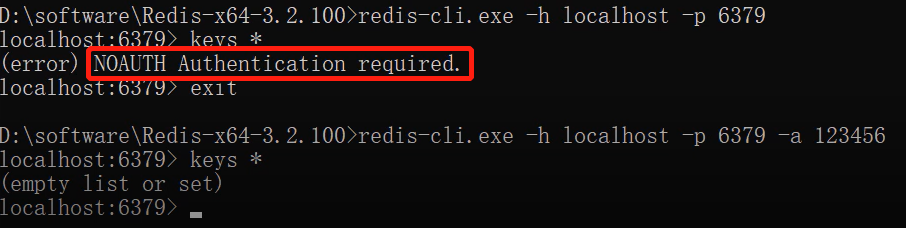 

此时，-h 和 -p 参数可省略不写。


#### 1.3.4 Redis客户端图形工具

默认提供的客户端连接工具界面不太友好，同时操作也较为麻烦，接下来，引入一个Redis客户端图形工具。

在当天资料中已提供安装包，直接安装即可。

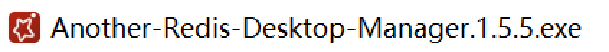 

安装完毕后，直接双击启动

**新建连接**

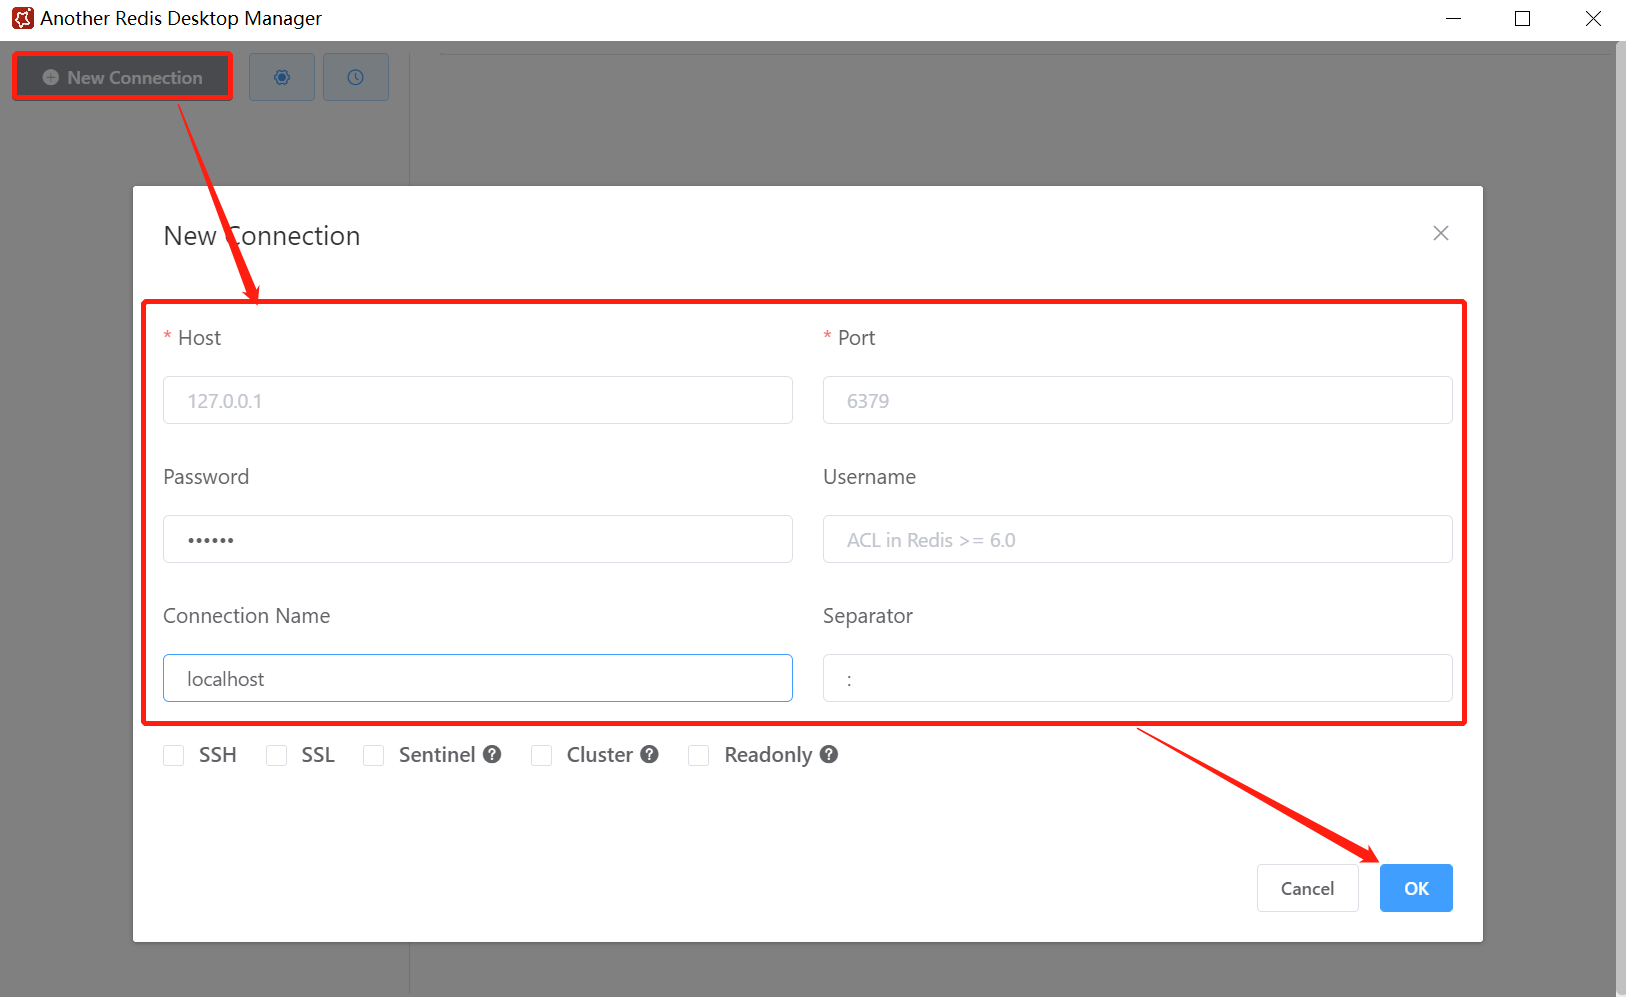  

**连接成功** 

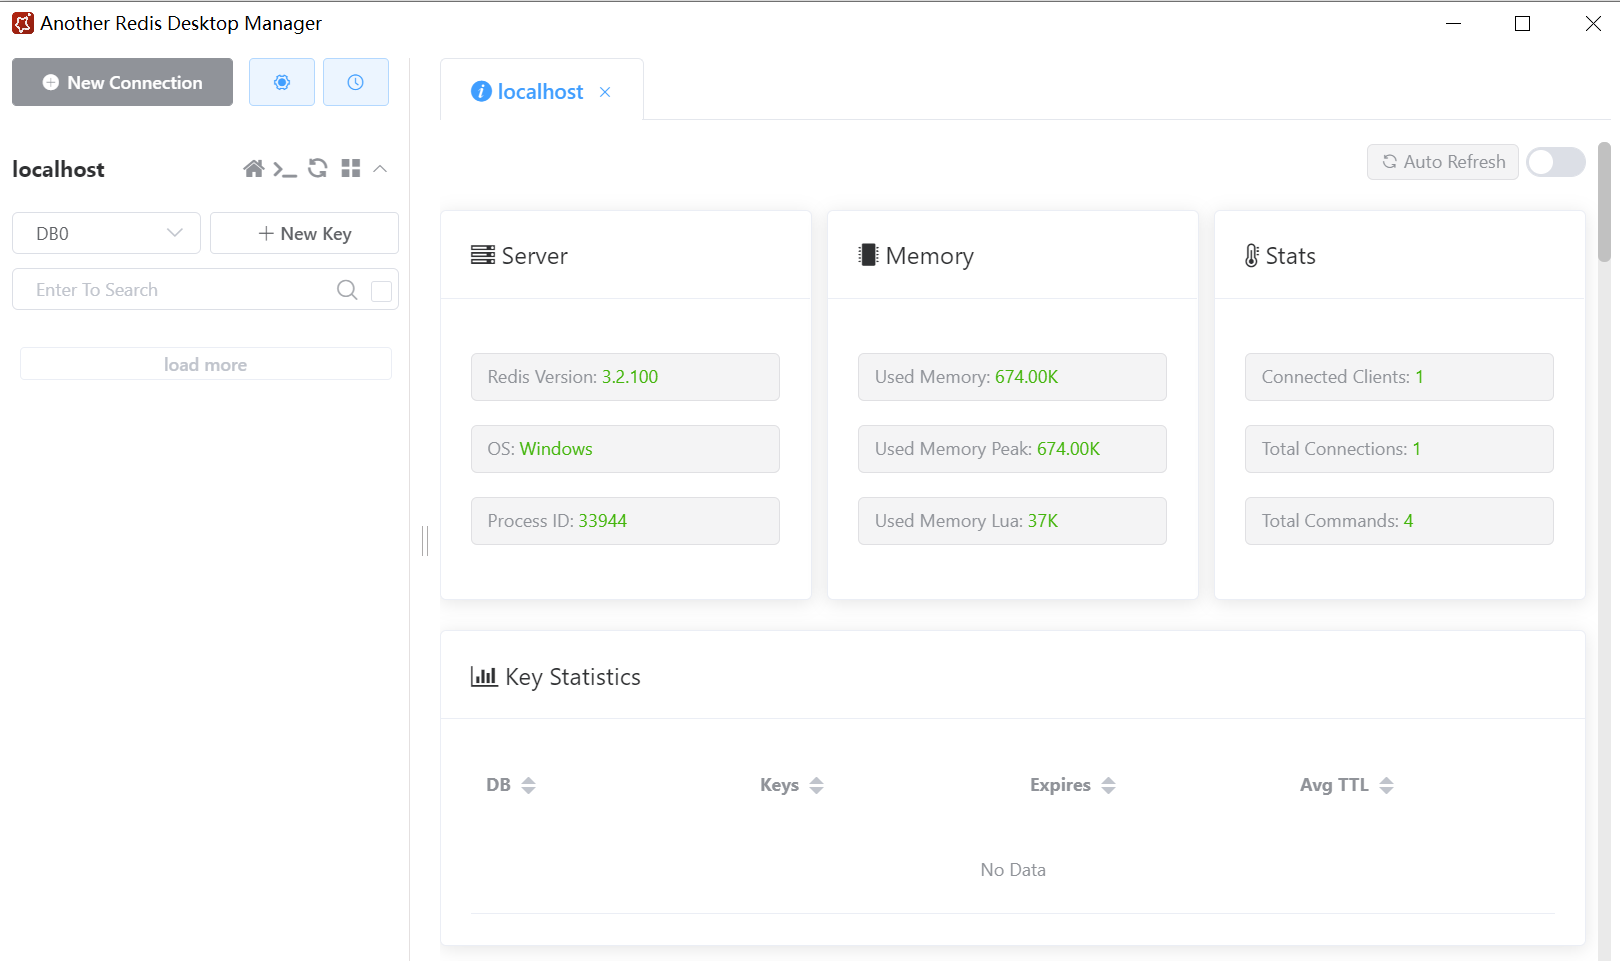


### 服务端、客户端与逻辑数据库（补充）

redis-server运行数据库服务，redis-cli是连接它的客户端。关闭客户端窗口不等于停止服务；在前台运行的课程服务窗口按Ctrl+C才会请求停止服务。

原文“未加密码连接失败”应更准确地理解：TCP连接可能成功，但执行命令会收到 `NOAUTH Authentication required`。认证后才可继续操作。

```text
redis-cli.exe -h localhost -p 6379
AUTH <你的Redis密码>
PING
SELECT 10
```

这些是命令行启动与连接后的命令，尖括号内容需替换；PING正常返回PONG。支持交互式密码输入的较新redis-cli也可使用 `--askpass`。讲义中的123456是演示密码，实际配置不要采用它；`-a`直接带密码可能出现在命令历史和进程参数中。

Redis配置文件中的requirepass用于服务认证，Java的password用于客户端提交凭据，两处要一致。修改了文件后，需要让实际运行服务加载新配置；改错文件或连接另一个实例不会生效。

默认独立Redis常见有16个逻辑数据库，编号0—15。db0和db10里可以存在相同key而互不相同；SELECT只改变当前连接选中的数据库。逻辑库不等于独立服务器，也不能替代权限隔离；Redis Cluster只支持db0，不能直接沿用database=10。

出现端口占用时，先确认是否已有课程Redis服务，避免再启动第二份。连接图形工具后也要选择与Java一致的db10。


## 2. Redis数据类型

> **PPT对照：** 第15—18页。


### 2.1 五种常用数据类型介绍

> **PPT对照：** 第16页。

Redis存储的是key-value结构的数据，其中key是字符串类型，value有5种常用的数据类型：

- 字符串 string
- 哈希 hash
- 列表 list
- 集合 set
- 有序集合 sorted set / zset


### 类型描述的是value的结构（补充）

所有key都作为字节序列处理，课程按字符串命名。value属于什么Redis类型，由使用的写命令决定：SET生成string、HSET生成hash、LPUSH生成list等。

Java里保存Integer不意味着Redis出现一种“integer类型”；序列化后的整数仍存到Redis string中。把多个字段存到Redis hash也不等于创建一张关系型表。

本章讲五种常用类型，并非Redis的完整类型清单；其他类型和结构按后续用途学习即可。


### 2.2 各种数据类型特点

> **PPT对照：** 第18页。

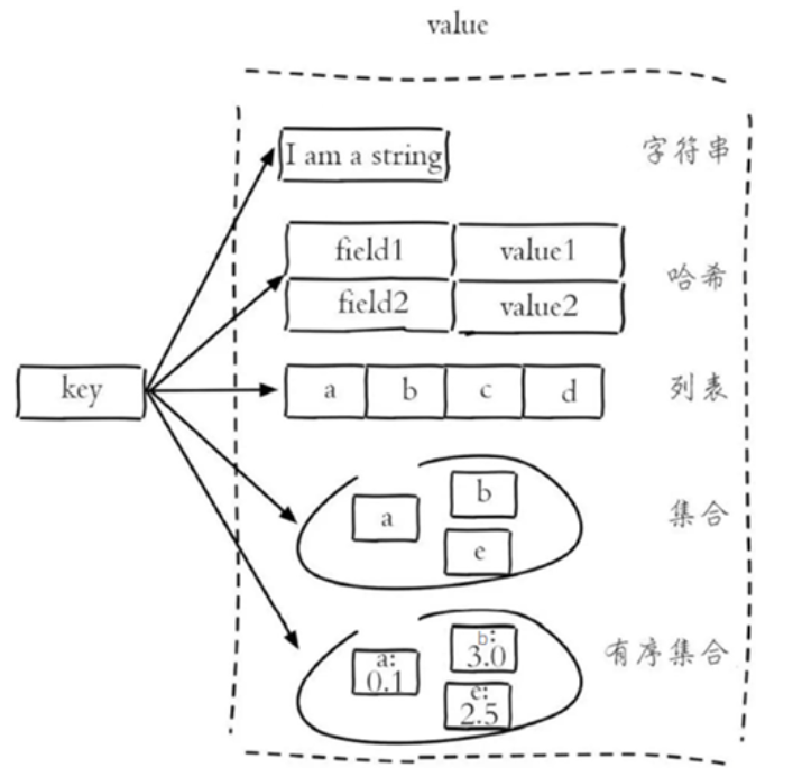 

**解释说明：**

- 字符串(string)：普通字符串，Redis中最简单的数据类型
- 哈希(hash)：也叫散列，类似于Java中的HashMap结构
- 列表(list)：按照插入顺序排序，可以有重复元素，类似于Java中的LinkedList
- 集合(set)：无序集合，没有重复元素，类似于Java中的HashSet
- 有序集合(sorted set/zset)：集合中每个元素关联一个分数(score)，根据分数升序排序，没有重复元素


### 按业务需求选类型（补充）

| 类型 | 是否有顺序 | 是否允许重复成员 | 本章理解例子 |
| --- | --- | --- | --- |
| string | 单个值 | 不适用 | 店铺状态、验证码、缓存文本 |
| hash | 字段无固定输出顺序 | field唯一，写入同名field会覆盖 | 用户简介的name、age字段 |
| list | 按左右端插入形成顺序 | 允许 | 有序任务或消息练习 |
| set | 无序 | 不允许重复member | 标签、去重、交并集 |
| zset | 按score排序 | member唯一，score可重复 | 分数榜、热度榜 |

zset中再次写入同一member会更新分数，不新增重复成员；相同score下按成员字节的字典序排序。榜单常需要分数倒序，原ZRANGE示例默认升序，要按展示方向选择命令。

这些与Java集合的类比用于理解结构，不代表实现细节完全相同。对同一个已有string key执行LPUSH等不匹配命令会报WRONGTYPE；先用TYPE确认，再选择正确操作，不要为了消除错误直接删业务数据。


## 3. Redis常用命令

> **PPT对照：** 第20—31页。


### 3.1 字符串操作命令

> **PPT对照：** 第21页。

Redis 中字符串类型常用命令：

- **SET** key value           设置指定key的值
- **GET** key                                        获取指定key的值
- **SETEX** key seconds value         设置指定key的值，并将 key 的过期时间设为 seconds 秒
- **SETNX** key value                        只有在 key    不存在时设置 key 的值

更多命令可以参考Redis中文网：https://www.redis.net.cn


### 字符串命令跟练与返回值（补充）

以下示例在独立练习key上执行，第一次跟练前确认没有同名前缀数据。

```redis
SET note:day05:name xiaoming
GET note:day05:name
SETEX note:day05:code 180 1234
TTL note:day05:code
SETNX note:day05:once first
SETNX note:day05:once second
GET note:day05:once
```

SET通常返回OK，GET返回xiaoming；TTL返回剩余秒数。首次SETNX返回1，第二次返回0，once仍为first。不存在时GET返回nil；它与字符串 `"null"` 和空字符串不同。

SET会覆盖旧值，普通SET通常也会清除旧过期时间；若要保留或设置TTL，须使用对应选项或带期限的写法。SETEX期限以秒为单位，Java示例的TimeUnit.MINUTES则以分钟为单位。

SETNX只保证“key不存在才设置”的单次原子操作。原测试中lock不设置过期时间，也没有校验释放者，不能当成完整分布式锁；真实锁还需要到期时间、持有者标识与原子校验释放等机制。


### 3.2 哈希操作命令

> **PPT对照：** 第23页。

Redis hash 是一个string类型的 field 和 value 的映射表，hash特别适合用于存储对象，常用命令：

- **HSET** key field value             将哈希表 key 中的字段 field 的值设为 value
- **HGET** key field                       获取存储在哈希表中指定字段的值
- **HDEL** key field                       删除存储在哈希表中的指定字段
- **HKEYS** key                              获取哈希表中所有字段
- **HVALS** key                              获取哈希表中所有值

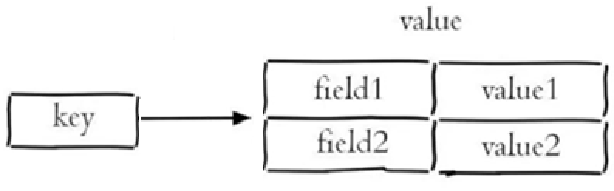


### hash的key与field不要混淆（补充）

```redis
HSET note:day05:user:100 name tom
HSET note:day05:user:100 age 20
HGET note:day05:user:100 name
HKEYS note:day05:user:100
HVALS note:day05:user:100
HDEL note:day05:user:100 age
```

外层key是note:day05:user:100，name与age是该hash内部的field。HDEL只删指定field；DEL外层key才删除整个hash。

HKEYS和HVALS没有保证你期望的显示顺序，不能将两次独立返回列表按索引拼成对象。如果要一起拿字段和值，可以使用HGETALL。对已有field再HSET会覆盖它；最后一个field删除后，空hash的key也会消失。


### 3.3 列表操作命令

> **PPT对照：** 第25页；讲义另补充BRPOP。

Redis 列表是简单的字符串列表，按照插入顺序排序，常用命令：

- **LPUSH** key value1 [value2]         将一个或多个值插入到列表头部
- **LRANGE** key start stop                获取列表指定范围内的元素
- **RPOP** key                                       移除并获取列表最后一个元素
- **LLEN** key                                        获取列表长度
- **BRPOP** key1 [key2 ] timeout       移出并获取列表的最后一个元素， 如果列表没有元素会阻塞列表直到等待超    时或发现可弹出元素为止

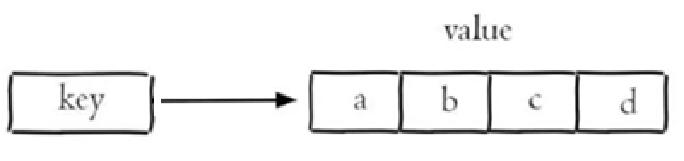


### LPUSH的多参数顺序（补充）

```redis
LPUSH note:day05:list a b c
LPUSH note:day05:list d
LRANGE note:day05:list 0 -1
RPOP note:day05:list
LLEN note:day05:list
```

在初始不存在的key上执行，第一次LPUSH后是 `[c,b,a]`，再插入d变为 `[d,c,b,a]`；RPOP得到a，剩余长度为3。不是按参数写成a,b,c就会在列表里保持这个方向。

LRANGE的start、stop都包含端点，-1表示最后一个元素。LPUSH从左放、RPOP从右取可以形成先进先出方向；从同侧放和取则类似栈。

讲义另介绍BRPOP，超时单位为秒，timeout=0会一直等待；练习可用有限等待：

```redis
BRPOP note:day05:queue 2
```

无元素时最多等待约2秒再返回nil，期间当前客户端无法继续执行其他命令。普通弹出会立即移除元素，不能单靠这个示例就获得可靠消息队列的确认、重试与故障恢复机制。


### 3.4 集合操作命令

> **PPT对照：** 第27页。

Redis set 是string类型的无序集合。集合成员是唯一的，这就意味着集合中不能出现重复的数据，常用命令：

- **SADD** key member1 [member2]            向集合添加一个或多个成员
- **SMEMBERS** key                                         返回集合中的所有成员
- **SCARD** key                                                  获取集合的成员数
- **SINTER** key1 [key2]                                   返回给定所有集合的交集
- **SUNION** key1 [key2]                                 返回所有给定集合的并集
- **SREM** key member1 [member2]            移除集合中一个或多个成员

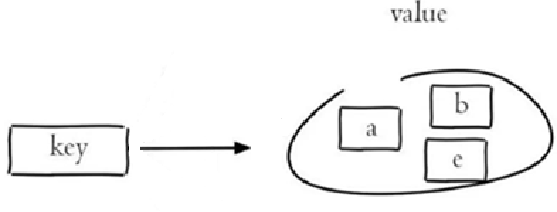


### 去重与交并集（补充）

```redis
SADD note:day05:set1 a b c a
SADD note:day05:set2 a b x
SCARD note:day05:set1
SINTER note:day05:set1 note:day05:set2
SUNION note:day05:set1 note:day05:set2
SREM note:day05:set1 a
```

初始空集合下，第一个SADD新增3个成员，重复a不会多占一条；SCARD为3。交集是a、b，并集是a、b、c、x，返回顺序不固定。

SINTER和SUNION只返回计算结果，不会自动修改原集合。测试时比较成员内容与数量，不能要求每次输出顺序都相同。


### 3.5 有序集合操作命令

> **PPT对照：** 第29页。

Redis有序集合是string类型元素的集合，且不允许有重复成员。每个元素都会关联一个double类型的分数。常用命令：

常用命令：

- **ZADD** key score1 member1 [score2 member2]     向有序集合添加一个或多个成员
- **ZRANGE** key start stop [WITHSCORES]                     通过索引区间返回有序集合中指定区间内的成员
- **ZINCRBY** key increment member                              有序集合中对指定成员的分数加上增量 increment
- **ZREM** key member [member ...]                                移除有序集合中的一个或多个成员

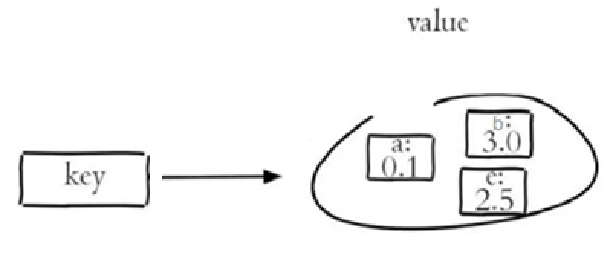


### score和member的参数位置（补充）

```redis
ZADD note:day05:rank 10 a 12 b 9 c
ZRANGE note:day05:rank 0 -1 WITHSCORES
ZINCRBY note:day05:rank 10 c
ZRANGE note:day05:rank 0 -1 WITHSCORES
```

初始顺序为c=9、a=10、b=12；给c加10后变为a=10、b=12、c=19。ZINCRBY是增加量，不是把分数改成10。相同分数可以对应不同成员，member仍唯一。

命令写 `ZADD key score member`，Spring的 `zSetOperations.add(key, member, score)` 则是member在前、score在后。按记忆照抄参数位置会存错成员或无法编译。

原Java测试先查看顺序，再给c加分，最后删除a和b，因此最后剩c的分数是19；若再次运行同一测试，add会重新设置同名成员的分数，跟练时明确已有状态。


### 3.6 通用命令

> **PPT对照：** 第31页。

Redis的通用命令是不分数据类型的，都可以使用的命令：

- KEYS pattern  查找所有符合给定模式( pattern)的 key 
- EXISTS key  检查给定 key 是否存在
- TYPE key  返回 key 所储存的值的类型
- DEL key  该命令用于在 key 存在是删除 key


### 类型、过期时间与查找范围（补充）

```redis
EXISTS note:day05:name
TYPE note:day05:name
SCAN 0 MATCH note:day05:* COUNT 100
TTL note:day05:code
DEL note:day05:name
```

TYPE返回string、hash等，不存在时为none。EXISTS返回存在的key数量；DEL返回实际删除的key数量，不存在的key删除结果为0。

TTL返回-1表示存在但没有到期时间，-2表示key不存在；正数或0表示剩余期限。店铺状态若不设TTL，正常应为-1，但仍可能受删除、淘汰、持久化恢复等因素影响。

课程的KEYS与 `redisTemplate.keys("*")`便于观察少量练习数据。KEYS会遍历匹配数据库的key并一次返回，数据量大时会阻塞其他操作；迭代查找用SCAN，并沿返回游标继续直到0。COUNT是工作量提示，不是每批精确条数；SCAN过程中可能返回重复key。

练习结束仅删除自己创建的具体key，不使用清空整个数据库的命令，避免误删SHOP_STATUS或其他课程数据。


## 4.在Java中操作Redis

> **PPT对照：** 第33—37页。


### 4.1 Redis的Java客户端

> **PPT对照：** 第34页。

前面我们讲解了Redis的常用命令，这些命令是我们操作Redis的基础，那么我们在java程序中应该如何操作Redis呢？这就需要使用Redis的Java客户端，就如同我们使用JDBC操作MySQL数据库一样。

Redis 的 Java 客户端很多，常用的几种：

- Jedis
- Lettuce
- Spring Data Redis

Spring 对 Redis 客户端进行了整合，提供了 Spring Data Redis，在Spring Boot项目中还提供了对应的Starter，即 spring-boot-starter-data-redis。

我们重点学习**Spring Data Redis**。


### Spring Data Redis与底层客户端的关系（补充）

Jedis和Lettuce是Redis客户端实现；Spring Data Redis提供统一的连接与操作抽象，RedisTemplate通过连接工厂使用底层客户端。它们不是三个完全同层级、互不相关的产品。

Spring Boot引入starter后可以创建连接工厂并自动提供模板。本章自定义RedisTemplate主要是明确key的序列化规则；不要因为有自定义配置就再重复new不受Spring管理的模板或底层连接。


### 4.2 Spring Data Redis使用方式

> **PPT对照：** 第36—37页。

#### 4.2.1 介绍

Spring Data Redis 是 Spring 的一部分，提供了在 Spring 应用中通过简单的配置就可以访问 Redis 服务，对 Redis 底层开发包进行了高度封装。在 Spring 项目中，可以使用Spring Data Redis来简化 Redis 操作。

网址：https://spring.io/projects/spring-data-redis

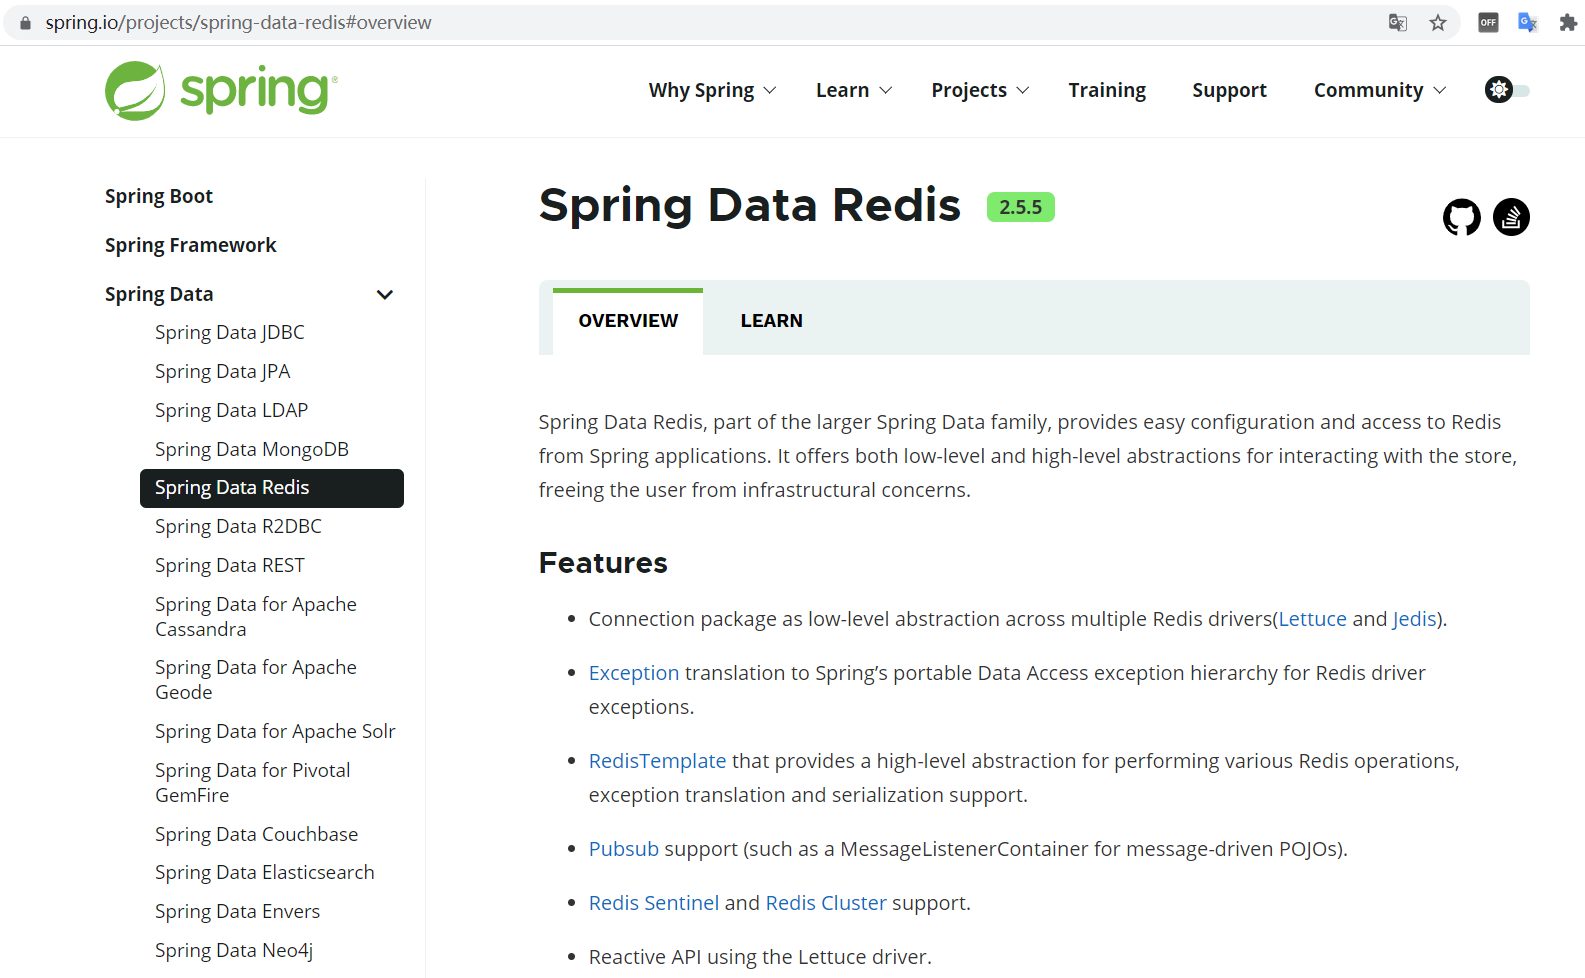 

Spring Boot提供了对应的Starter，maven坐标：

```xml
<dependency>
	<groupId>org.springframework.boot</groupId>
	<artifactId>spring-boot-starter-data-redis</artifactId>
</dependency>
```

Spring Data Redis中提供了一个高度封装的类：**RedisTemplate**，对相关api进行了归类封装,将同一类型操作封装为operation接口，具体分类如下：

- ValueOperations：string数据操作
- SetOperations：set类型数据操作
- ZSetOperations：zset类型数据操作
- HashOperations：hash类型的数据操作
- ListOperations：list类型的数据操作


#### 4.2.2 环境搭建

进入到sky-server模块

**1). 导入Spring Data Redis的maven坐标(已完成)**

```xml
<dependency>
     <groupId>org.springframework.boot</groupId>
     <artifactId>spring-boot-starter-data-redis</artifactId>
</dependency>
```


**2). 配置Redis数据源**

在application-dev.yml中添加

```yaml
sky:
  redis:
    host: localhost
    port: 6379
    password: 123456
    database: 10
```

**解释说明：**

database:指定使用Redis的哪个数据库，Redis服务启动后默认有16个数据库，编号分别是从0到15。

可以通过修改Redis配置文件来指定数据库的数量。

在application.yml中添加读取application-dev.yml中的相关Redis配置

```yaml
spring:
  profiles:
    active: dev
  redis:
    host: ${sky.redis.host}
    port: ${sky.redis.port}
    password: ${sky.redis.password}
    database: ${sky.redis.database}
```


**3). 编写配置类，创建RedisTemplate对象**

```java
package com.sky.config;

import lombok.extern.slf4j.Slf4j;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;
import org.springframework.data.redis.connection.RedisConnectionFactory;
import org.springframework.data.redis.core.RedisTemplate;
import org.springframework.data.redis.serializer.StringRedisSerializer;

@Configuration
@Slf4j
public class RedisConfiguration {

    @Bean
    public RedisTemplate redisTemplate(RedisConnectionFactory redisConnectionFactory){
        log.info("开始创建redis模板对象...");
        RedisTemplate redisTemplate = new RedisTemplate();
        //设置redis的连接工厂对象
        redisTemplate.setConnectionFactory(redisConnectionFactory);
        //设置redis key的序列化器
        redisTemplate.setKeySerializer(new StringRedisSerializer());
        return redisTemplate;
    }
}
```

**解释说明：**

当前配置类不是必须的，因为 Spring Boot 框架会自动装配 RedisTemplate 对象，但是默认的key序列化器为

JdkSerializationRedisSerializer，导致我们存到Redis中后的数据和原始数据有差别，故设置为

StringRedisSerializer序列化器。


**4). 通过RedisTemplate对象操作Redis**

在test下新建测试类

```java
package com.sky.test;

import org.junit.jupiter.api.Test;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.boot.test.context.SpringBootTest;
import org.springframework.data.redis.core.*;

@SpringBootTest
public class SpringDataRedisTest {
    @Autowired
    private RedisTemplate redisTemplate;

    @Test
    public void testRedisTemplate(){
        System.out.println(redisTemplate);
        //string数据操作
        ValueOperations valueOperations = redisTemplate.opsForValue();
        //hash类型的数据操作
        HashOperations hashOperations = redisTemplate.opsForHash();
        //list类型的数据操作
        ListOperations listOperations = redisTemplate.opsForList();
        //set类型数据操作
        SetOperations setOperations = redisTemplate.opsForSet();
        //zset类型数据操作
        ZSetOperations zSetOperations = redisTemplate.opsForZSet();
    }
}
```

测试：

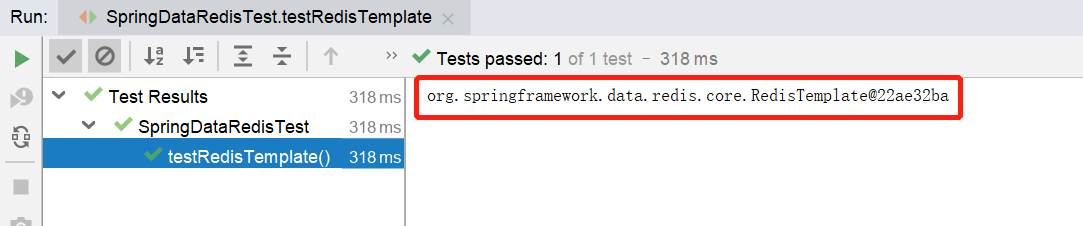 

说明RedisTemplate对象注入成功，并且通过该RedisTemplate对象获取操作5种数据类型相关对象。

上述环境搭建完毕后，接下来，我们就来具体对常见5种数据类型进行操作。


#### 4.2.3 操作常见类型数据

**1). 操作字符串类型数据**

```java
	/**
     * 操作字符串类型的数据
     */
    @Test
    public void testString(){
        // set get setex setnx
        redisTemplate.opsForValue().set("name","小明");
        String city = (String) redisTemplate.opsForValue().get("name");
        System.out.println(city);
        redisTemplate.opsForValue().set("code","1234",3, TimeUnit.MINUTES);
        redisTemplate.opsForValue().setIfAbsent("lock","1");
        redisTemplate.opsForValue().setIfAbsent("lock","2");
    }
```


**2). 操作哈希类型数据**

```java
	/**
     * 操作哈希类型的数据
     */
    @Test
    public void testHash(){
        //hset hget hdel hkeys hvals
        HashOperations hashOperations = redisTemplate.opsForHash();

        hashOperations.put("100","name","tom");
        hashOperations.put("100","age","20");

        String name = (String) hashOperations.get("100", "name");
        System.out.println(name);

        Set keys = hashOperations.keys("100");
        System.out.println(keys);

        List values = hashOperations.values("100");
        System.out.println(values);

        hashOperations.delete("100","age");
    }
```


**3). 操作列表类型数据**

```java
	/**
     * 操作列表类型的数据
     */
    @Test
    public void testList(){
        //lpush lrange rpop llen
        ListOperations listOperations = redisTemplate.opsForList();

        listOperations.leftPushAll("mylist","a","b","c");
        listOperations.leftPush("mylist","d");

        List mylist = listOperations.range("mylist", 0, -1);
        System.out.println(mylist);

        listOperations.rightPop("mylist");

        Long size = listOperations.size("mylist");
        System.out.println(size);
    }
```


**4). 操作集合类型数据**

```java
	/**
     * 操作集合类型的数据
     */
    @Test
    public void testSet(){
        //sadd smembers scard sinter sunion srem
        SetOperations setOperations = redisTemplate.opsForSet();

        setOperations.add("set1","a","b","c","d");
        setOperations.add("set2","a","b","x","y");

        Set members = setOperations.members("set1");
        System.out.println(members);

        Long size = setOperations.size("set1");
        System.out.println(size);

        Set intersect = setOperations.intersect("set1", "set2");
        System.out.println(intersect);

        Set union = setOperations.union("set1", "set2");
        System.out.println(union);

        setOperations.remove("set1","a","b");
    }
```


**5). 操作有序集合类型数据**

```java
	/**
     * 操作有序集合类型的数据
     */
    @Test
    public void testZset(){
        //zadd zrange zincrby zrem
        ZSetOperations zSetOperations = redisTemplate.opsForZSet();

        zSetOperations.add("zset1","a",10);
        zSetOperations.add("zset1","b",12);
        zSetOperations.add("zset1","c",9);

        Set zset1 = zSetOperations.range("zset1", 0, -1);
        System.out.println(zset1);

        zSetOperations.incrementScore("zset1","c",10);

        zSetOperations.remove("zset1","a","b");
    }
```


**6). 通用命令操作**

```java
	/**
     * 通用命令操作
     */
    @Test
    public void testCommon(){
        //keys exists type del
        Set keys = redisTemplate.keys("*");
        System.out.println(keys);

        Boolean name = redisTemplate.hasKey("name");
        Boolean set1 = redisTemplate.hasKey("set1");

        for (Object key : keys) {
            DataType type = redisTemplate.type(key);
            System.out.println(type.name());
        }

        redisTemplate.delete("mylist");
    }
```


### Java跟练的配置与序列化（补充与勘误）

#### 1. 配置连接到哪个实例与数据库

原讲义dev配置通过sky.redis提供值，主配置spring.redis引用它；PPT第36页直接写spring.redis，且没指定database，通常使用默认db0。按讲义完整实现跟练时使用db10；不是PPT中的状态与讲义中的状态自动跨库共享。

host=localhost指Java进程所在环境。若Java在容器中运行，它不一定指宿主机；连接失败先核对实际部署位置。原配置沿用课程所用Spring Boot版本；换到Spring Boot 3.x时Redis属性通常放在 `spring.data.redis`，要按自己的版本调整，不能只改依赖版本却照抄旧前缀。

密码123456仅是原文演示值。可以继续保留sky.redis的桥接结构，通过环境变量提供真实配置：

```yaml
sky:
  redis:
    host: ${REDIS_HOST:localhost}
    port: ${REDIS_PORT:6379}
    password: ${REDIS_PASSWORD}
    database: ${REDIS_DATABASE:10}
```

无认证的本地实例应按实际配置去掉password项，或明确允许空值；不要把未设置的占位符错误当成Redis连接错误。

#### 2. 原配置只改变key，没改变value

| 数据部分 | 原课程配置 | 观察结果 |
| --- | --- | --- |
| 外层key | StringRedisSerializer | SHOP_STATUS、name等key可直接读懂 |
| 普通value | 默认JDK序列化 | Integer、String等编码成Java序列化字节 |
| hash内部field | 默认JDK序列化 | HKEYS可能显示不可读的编码内容 |
| hash内部value | 默认JDK序列化 | 需同一序列化规则读取 |
| list/set成员 | 默认value序列化 | 不等于命令行写入的纯文本成员 |

因此 `TYPE SHOP_STATUS`仍返回string，但 `GET SHOP_STATUS`可能显示二进制转义内容。这不是多出一个Redis“Java类型”，而是string里保存的字节格式。

课程Java把Integer 1写入后，同一模板读回Integer 1；命令行直接SET写入ASCII文本1后，JDK反序列化器无法解析。换序列化器也不会自动重写旧key，可能出现SerializationException或ClassCastException。

可以保留原配置以完成课程；如需全部使用文本，使用StringRedisTemplate并把营业状态转换为字符串，两个读端和写端必须一起调整。hash也要一致设置hashKeySerializer/hashValueSerializer，不能只改外层key就期望全部可读。

#### 3. 注入成功不等于连接成功

原testRedisTemplate只是打印模板、取得operations对象，通常没有向Redis发送数据命令；它不能单独证明网络、密码与db10正确。运行一个真实set/get或PING操作才验证连接。

原测试片段拼进类时，补齐用到的imports：

```java
import java.util.List;
import java.util.Set;
import java.util.concurrent.TimeUnit;
import org.springframework.data.redis.connection.DataType;
```

模板与Operations使用原始泛型类型是教学简写，强制转换可能在混入不同数据格式时失败。实际代码应按存储模型设置泛型与序列化规则，不凭类型声明假设底层字节一定正确。

#### 4. 命令与Java方法对照

| Redis命令 | RedisTemplate方法 |
| --- | --- |
| SET / GET | opsForValue().set / get |
| SETEX | opsForValue().set(key, value, timeout, unit) |
| SETNX | opsForValue().setIfAbsent |
| HSET / HGET / HDEL | opsForHash().put / get / delete |
| LPUSH / LRANGE / RPOP / LLEN | opsForList().leftPush / range / rightPop / size |
| SADD / SMEMBERS / SCARD | opsForSet().add / members / size |
| SINTER / SUNION / SREM | opsForSet().intersect / union / remove |
| ZADD / ZRANGE / ZINCRBY / ZREM | opsForZSet().add / range / incrementScore / remove |
| EXISTS / TYPE / DEL | hasKey / type / delete |

原testString的code期限是3分钟，即约180秒；lock的setIfAbsent没有期限。原testList返回d,c,b,a，弹出a后长度3。原hash、set、zset返回的集合或字段顺序不要机械对应截图顺序。

测试只操作专门的练习数据；不同@Test方法的执行顺序不应当作依赖，每个示例都应明确它运行前的key状态。使用共享课程数据库时不要随意清空全部key。


## 5. 店铺营业状态设置

> **PPT对照：** 第39—48页。


### 5.1 需求分析和设计

> **PPT对照：** 第40—42页。

#### 5.1.1 产品原型

进到苍穹外卖后台，显示餐厅的营业状态，营业状态分为**营业中**和**打烊中**，若当前餐厅处于营业状态，自动接收任何订单，客户可在小程序进行下单操作；若当前餐厅处于打烊状态，不接受任何订单，客户便无法在小程序进行下单操作。

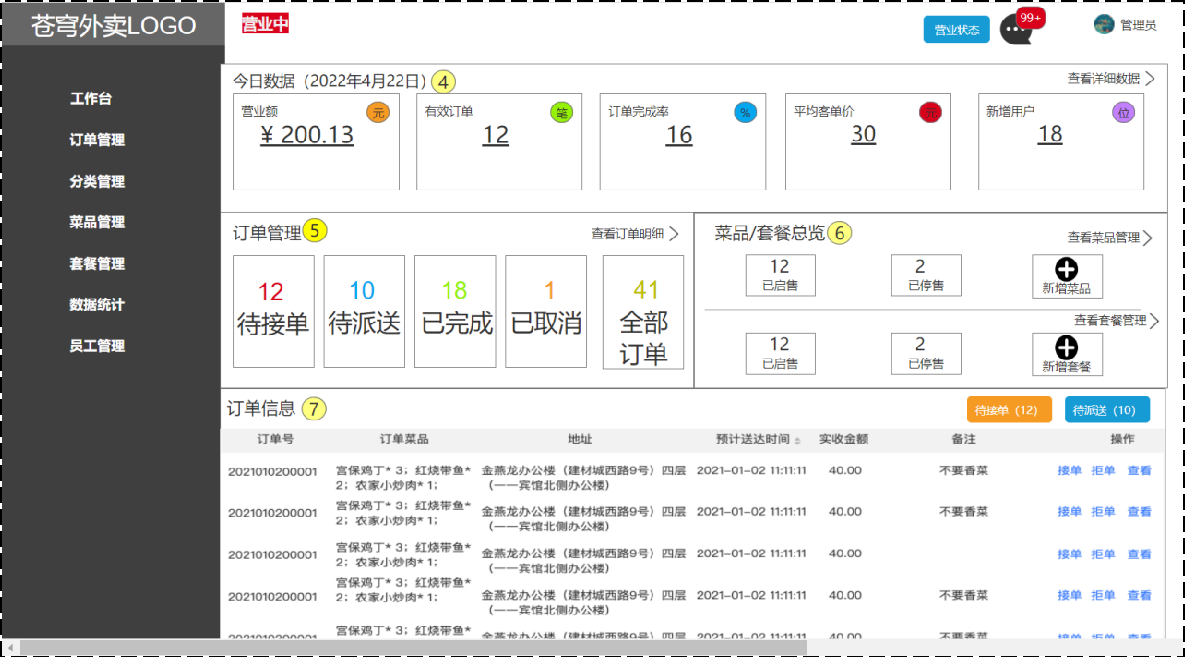 

点击**营业状态**按钮时，弹出更改营业状态

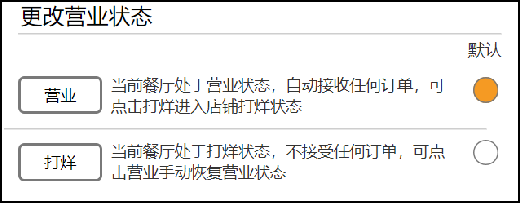 

选择营业，设置餐厅为**营业中**状态

选择打烊，设置餐厅为**打烊中**状态

**状态说明：**

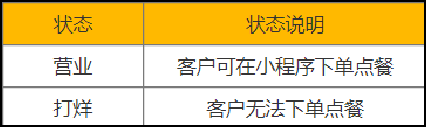 


#### 5.1.2 接口设计

根据上述原型图设计接口，共包含3个接口。

**接口设计：**

- 设置营业状态
- 管理端查询营业状态
- 用户端查询营业状态

**注：**从技术层面分析，其实管理端和用户端查询营业状态时，可通过一个接口去实现即可。因为营业状态是一致的。但是，本项目约定：

- **管理端**发出的请求，统一使用/admin作为前缀。
- **用户端**发出的请求，统一使用/user作为前缀。

因为访问路径不一致，故分为两个接口实现。

**1). 设置营业状态**

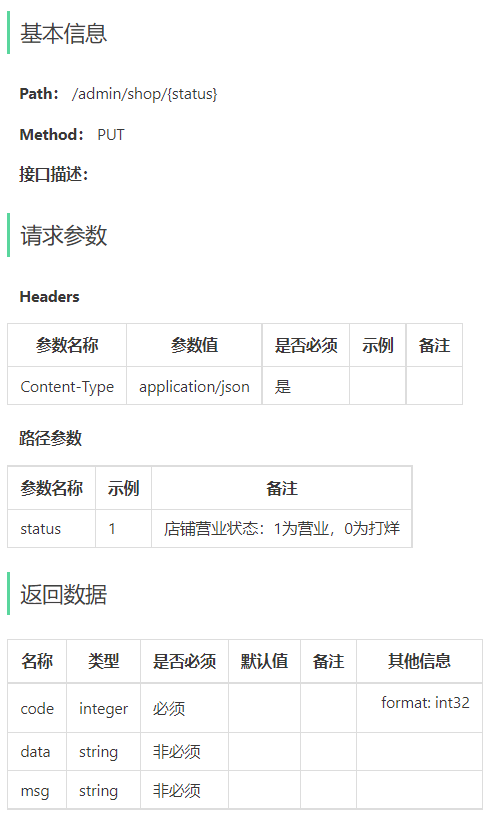 


**2). 管理端营业状态**

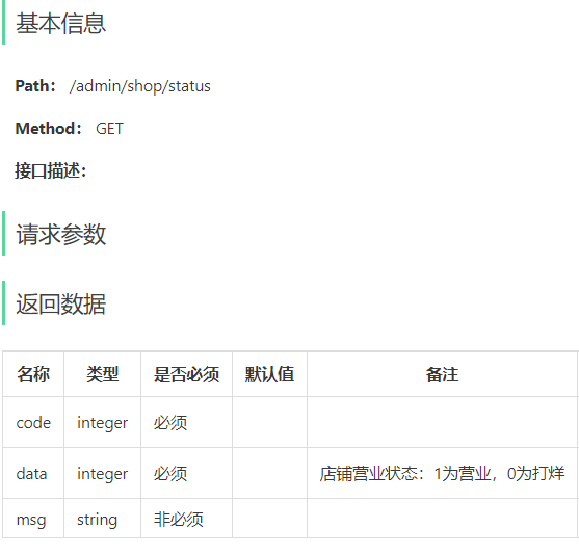 


**3). 用户端营业状态**

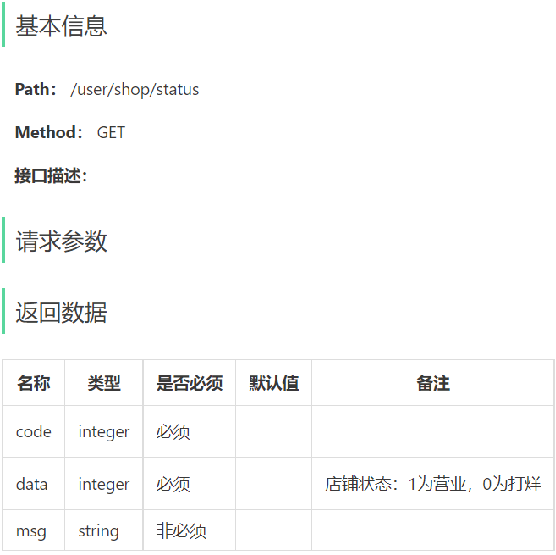 


#### 5.1.3 营业状态存储方式

虽然，可以通过一张表来存储营业状态数据，但整个表中只有一个字段，所以意义不大。

营业状态数据存储方式：基于Redis的字符串来进行存储

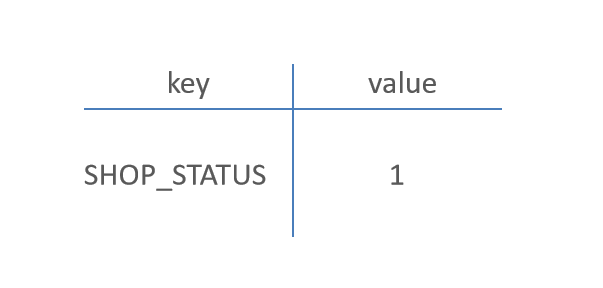 

**约定：**1表示营业 0表示打烊


### 一份状态、两个查询入口（补充）

管理端与用户端显示同一个状态，所以读取同一个Redis实例、逻辑数据库和key；两个HTTP路径是端的划分，并非两份独立状态。

写接口只允许有权限的管理端调用。URL前缀、Controller包名和接口文档分组都不会自动实现权限控制，仍需对应拦截器及权限规则。

讲义说“用表存一个字段意义不大”，这是教学简化，并非数据库不能存配置。若营业状态要求持久可靠，可以有店铺配置表作为来源；只存Redis时要定义初始化、持久化恢复、淘汰和故障策略。

本章实现的是设置与查询状态，并没有给出完整订单提交逻辑。后续下单业务还应在服务端检查营业状态；只在小程序里禁用按钮，无法防止直接调用下单接口。页面看到营业与真正提交之间还可能发生打烊，应定义以哪个业务检查时刻为准。


### 5.2 代码开发

> **PPT对照：** 第44—46页。

#### 5.2.1 设置营业状态

在sky-server模块中，创建ShopController.java

**根据接口定义创建ShopController的setStatus设置营业状态方法：**

```java
package com.sky.controller.admin;

import com.sky.result.Result;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.data.redis.core.RedisTemplate;
import org.springframework.web.bind.annotation.PathVariable;
import org.springframework.web.bind.annotation.PutMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

@RestController("adminShopController")
@RequestMapping("/admin/shop")
@Api(tags = "店铺相关接口")
@Slf4j
public class ShopController {

    public static final String KEY = "SHOP_STATUS";

    @Autowired
    private RedisTemplate redisTemplate;

    /**
     * 设置店铺的营业状态
     * @param status
     * @return
     */
    @PutMapping("/{status}")
    @ApiOperation("设置店铺的营业状态")
    public Result setStatus(@PathVariable Integer status){
        log.info("设置店铺的营业状态为：{}",status == 1 ? "营业中" : "打烊中");
        redisTemplate.opsForValue().set(KEY,status);
        return Result.success();
    }
}
```


#### 5.2.2 管理端查询营业状态

**根据接口定义创建ShopController的getStatus查询营业状态方法：**

```java
	/**
     * 获取店铺的营业状态
     * @return
     */
    @GetMapping("/status")
    @ApiOperation("获取店铺的营业状态")
    public Result<Integer> getStatus(){
        Integer status = (Integer) redisTemplate.opsForValue().get(KEY);
        log.info("获取到店铺的营业状态为：{}",status == 1 ? "营业中" : "打烊中");
        return Result.success(status);
    }
```


#### 5.2.3 用户端查询营业状态

创建com.sky.controller.user包，在该包下创建ShopController.java

**根据接口定义创建ShopController的getStatus查询营业状态方法：**

```java
package com.sky.controller.user;

import com.sky.result.Result;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.data.redis.core.RedisTemplate;
import org.springframework.web.bind.annotation.*;

@RestController("userShopController")
@RequestMapping("/user/shop")
@Api(tags = "店铺相关接口")
@Slf4j
public class ShopController {

    public static final String KEY = "SHOP_STATUS";

    @Autowired
    private RedisTemplate redisTemplate;

    /**
     * 获取店铺的营业状态
     * @return
     */
    @GetMapping("/status")
    @ApiOperation("获取店铺的营业状态")
    public Result<Integer> getStatus(){
        Integer status = (Integer) redisTemplate.opsForValue().get(KEY);
        log.info("获取到店铺的营业状态为：{}",status == 1 ? "营业中" : "打烊中");
        return Result.success(status);
    }
}
```


### 状态校验与未初始化勘误（重点）

原setStatus不校验范围，status=2也会写入Redis，日志却显示“打烊中”。原getStatus读到null后执行 `status == 1`，会自动拆箱导致空指针；两个端都有这个问题。

`@RestController("adminShopController")`和 `@RestController("userShopController")`用于区分两个同名类的Spring Bean名称。RequestMapping再区分HTTP路径；两类只因Java包不同，不代表默认bean名称一定不冲突。

#### 兼容课程JDK序列化的修正

下面把共享规则放到一个Service，两个Controller复用它，继续注入原课程配置的RedisTemplate，不改变已有value字节格式。**本补充约定缺失状态先按0打烊展示**，这是新增约定，原文没有定义默认值；Redis连接异常或格式错误仍返回失败，不伪装成合法状态。

在sky-server增加 `com.sky.service.ShopStatusService`：

```java
package com.sky.service;

import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.beans.factory.annotation.Qualifier;
import org.springframework.data.redis.core.RedisTemplate;
import org.springframework.stereotype.Service;

@Service
public class ShopStatusService {
    private static final String KEY = "SHOP_STATUS";

    @Autowired
    @Qualifier("redisTemplate")
    private RedisTemplate<String, Object> redisTemplate;

    public void setStatus(Integer status) {
        if (status == null || (status != 0 && status != 1)) {
            throw new IllegalArgumentException("营业状态只允许0或1");
        }
        // 存入Integer，兼容原课程JDK序列化；不设置过期时间。
        redisTemplate.opsForValue().set(KEY, status);
    }

    public Integer getStatus() {
        Object value = redisTemplate.opsForValue().get(KEY);
        if (value == null) {
            return 0;
        }
        if (!(value instanceof Integer)) {
            throw new IllegalStateException("营业状态数据类型不正确");
        }
        Integer status = (Integer) value;
        if (status != 0 && status != 1) {
            throw new IllegalStateException("营业状态数据不合法");
        }
        return status;
    }
}
```

管理端原Controller保留路径、Bean名称与注解，改为注入Service并替换两个方法：

```java
@Autowired
private com.sky.service.ShopStatusService shopStatusService;

@PutMapping("/{status}")
public Result<Void> setStatus(@PathVariable("status") Integer status) {
    shopStatusService.setStatus(status);
    return Result.success();
}

@GetMapping("/status")
public Result<Integer> getStatus() {
    return Result.success(shopStatusService.getStatus());
}
```

用户端Controller也注入同一Service，替换查询方法：

```java
@Autowired
private com.sky.service.ShopStatusService shopStatusService;

@GetMapping("/status")
public Result<Integer> getStatus() {
    return Result.success(shopStatusService.getStatus());
}
```

管理端原完整类的import列表没有GetMapping，追加方法时需补 `org.springframework.web.bind.annotation.GetMapping`；API文档注解可沿用原文。补充异常应接入项目现有全局处理器，IllegalArgumentException并不会自动变成业务Result。Redis连接或反序列化异常也应统一返回可辨识错误。

GET缺失时返回0只决定响应，不会把key写回Redis。初始化可在测试库通过受保护的 `PUT /admin/shop/0` 完成：它用与查询一致的模板写Integer，不使用命令行SET混写。运行中更新是单次SET，正常最后完成的写入决定当前状态；不需要照搬菜品多表的数据库事务。

#### 如果要改用纯字符串存储

这是一套替代方案，不与上面的Integer/JDK存储混用。可以在Service中改用StringRedisTemplate，写入和读取一起调整：

```java
@Autowired
private org.springframework.data.redis.core.StringRedisTemplate stringRedisTemplate;

// 已校验status只能为0或1后写入。
stringRedisTemplate.opsForValue().set("SHOP_STATUS", status.toString());

// 查询方法中的读取和转换；缺失按补充约定返回0。
String raw = stringRedisTemplate.opsForValue().get("SHOP_STATUS");
if (raw == null) {
    return 0;
}
if (!"0".equals(raw) && !"1".equals(raw)) {
    throw new IllegalStateException("营业状态数据不合法");
}
return Integer.valueOf(raw);
```

这是方法内替换片段，不是完整新类。切换之前先确认旧SHOP_STATUS是否为JDK字节，并安排只迁移这个key，两个端和写端同时切换；不要清空整个Redis数据库。切换完成后命令行与Java才可以按相同纯文本规则读写。

#### 状态不设TTL，也要考虑恢复

原set没有到期参数，正常写入后TTL为-1。数据库0和10不同、Redis恢复了较旧持久化快照、key被删除或受淘汰策略影响，仍可能让读端看不到最新状态。选择缺失打烊、报错或从持久化配置恢复应形成业务约定；不能因为“基于内存速度快”就跳过状态可靠性问题。


### 5.3 功能测试

> **PPT对照：** 第48页；接口分组代码由讲义展开。

#### 5.3.1 接口文档测试

**启动服务：**访问http://localhost:8080/doc.html，打开店铺相关接口

**注意：**使用admin用户登录重新获取token，防止token失效。

**设置营业状态：**

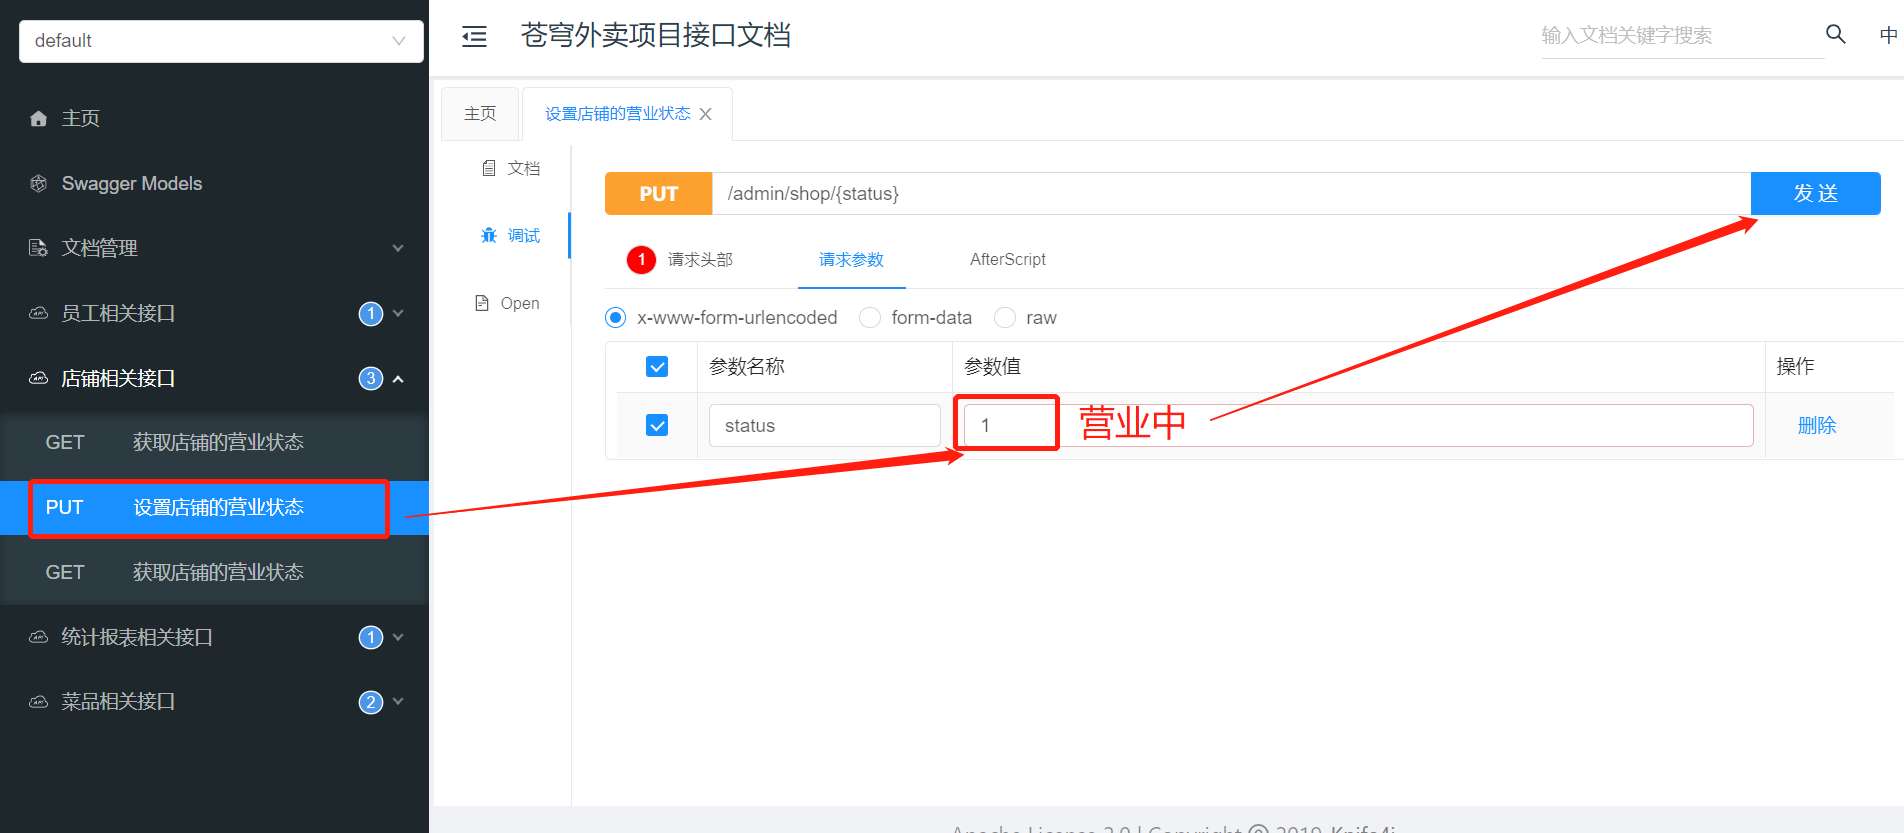 

点击发送

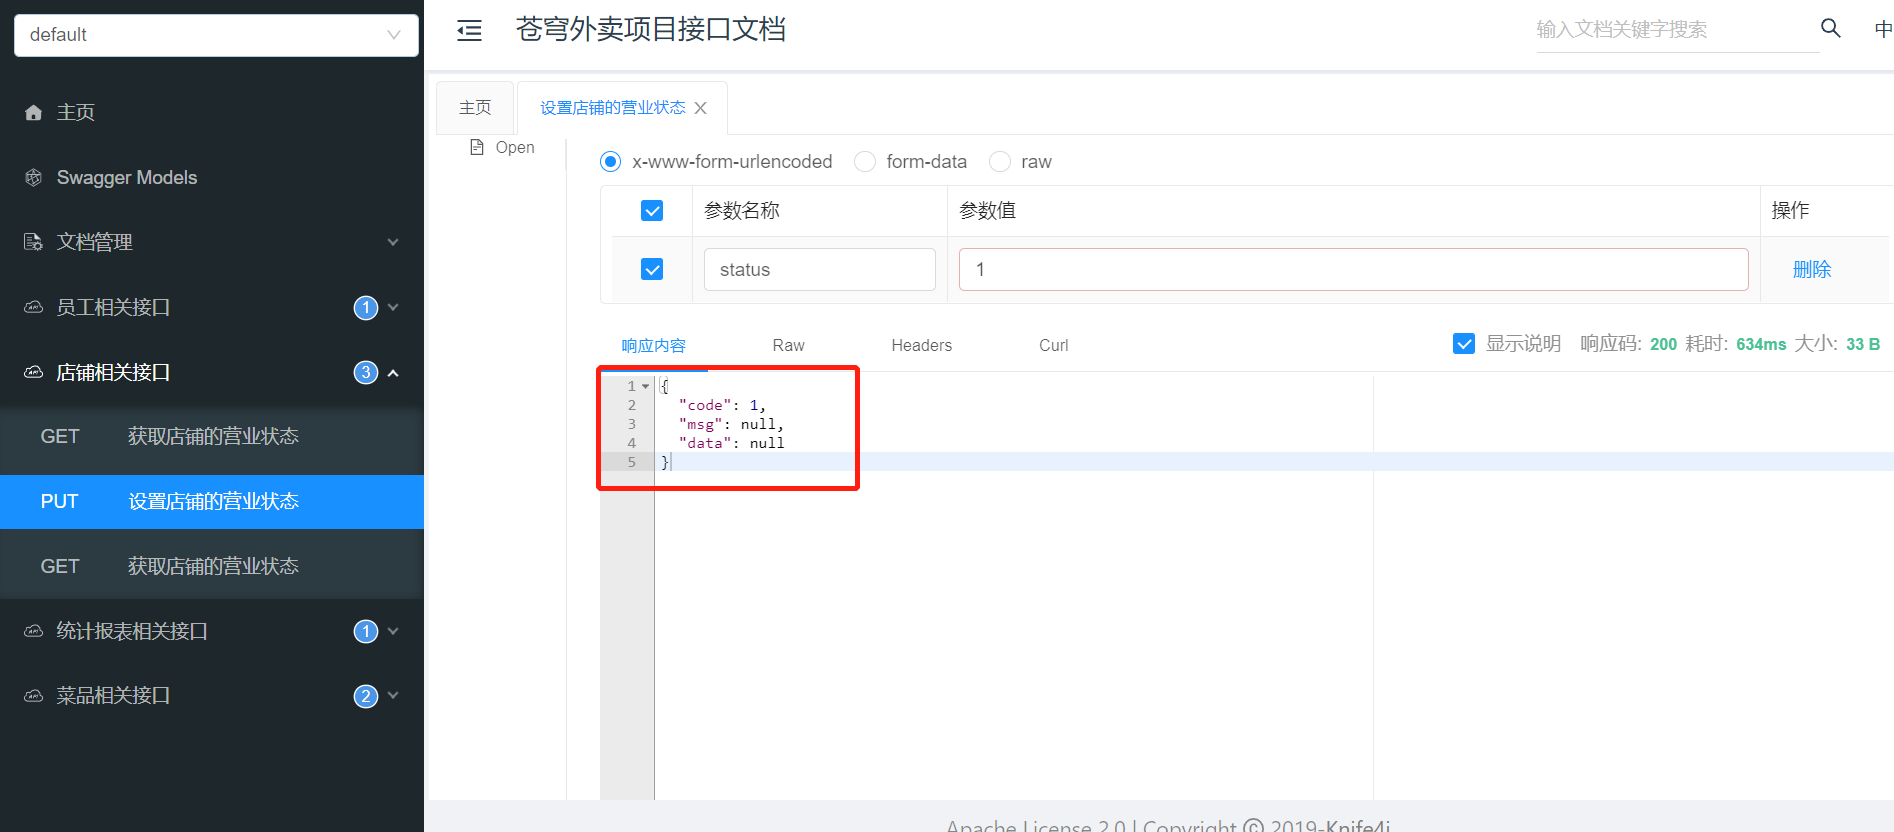 

查看Idea控制台日志

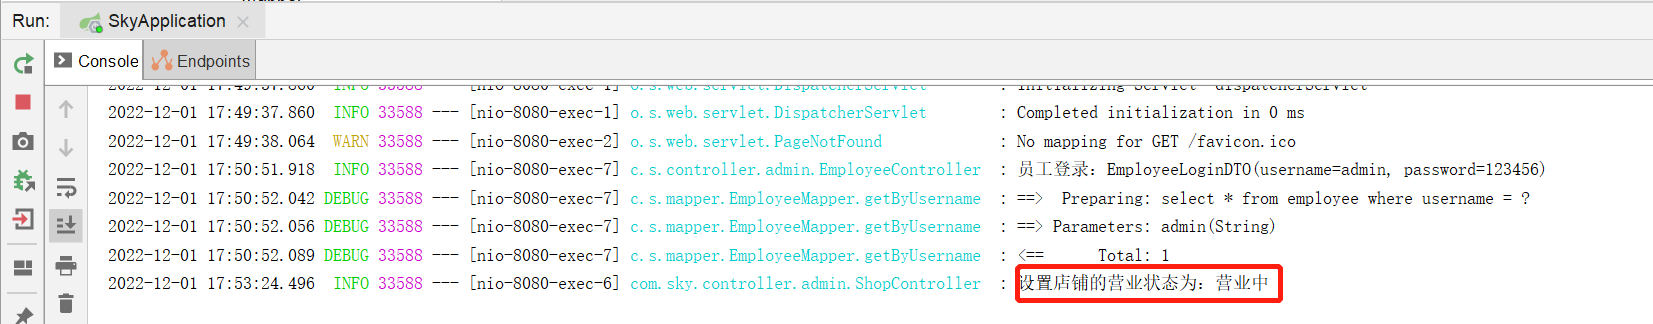 

查看Redis中数据

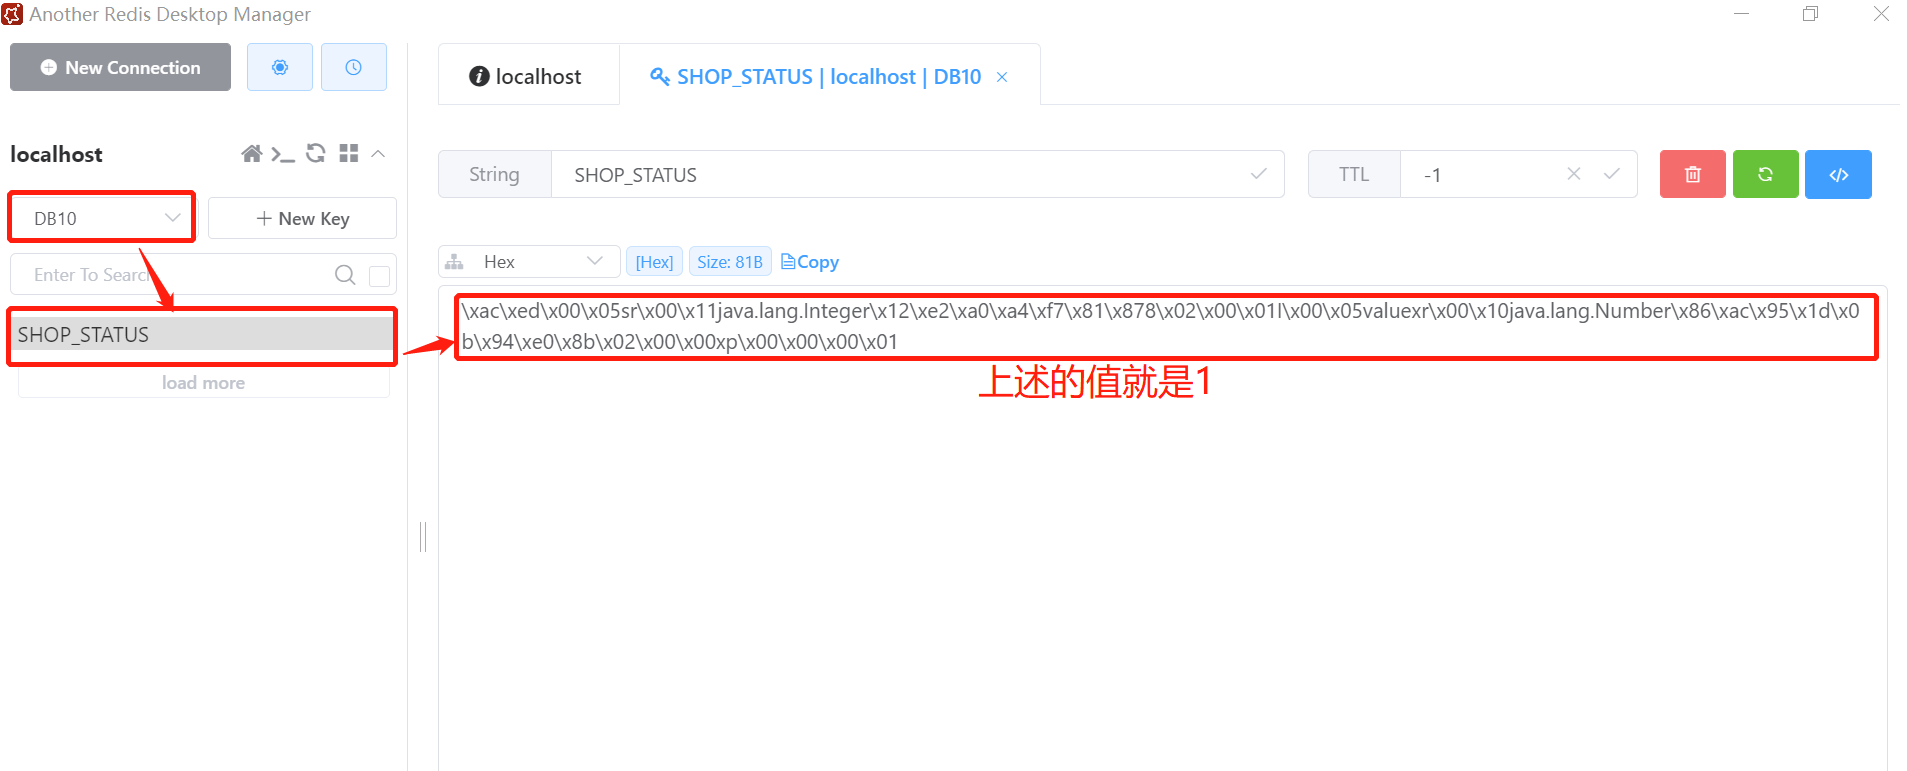 


**管理端查询营业状态：**

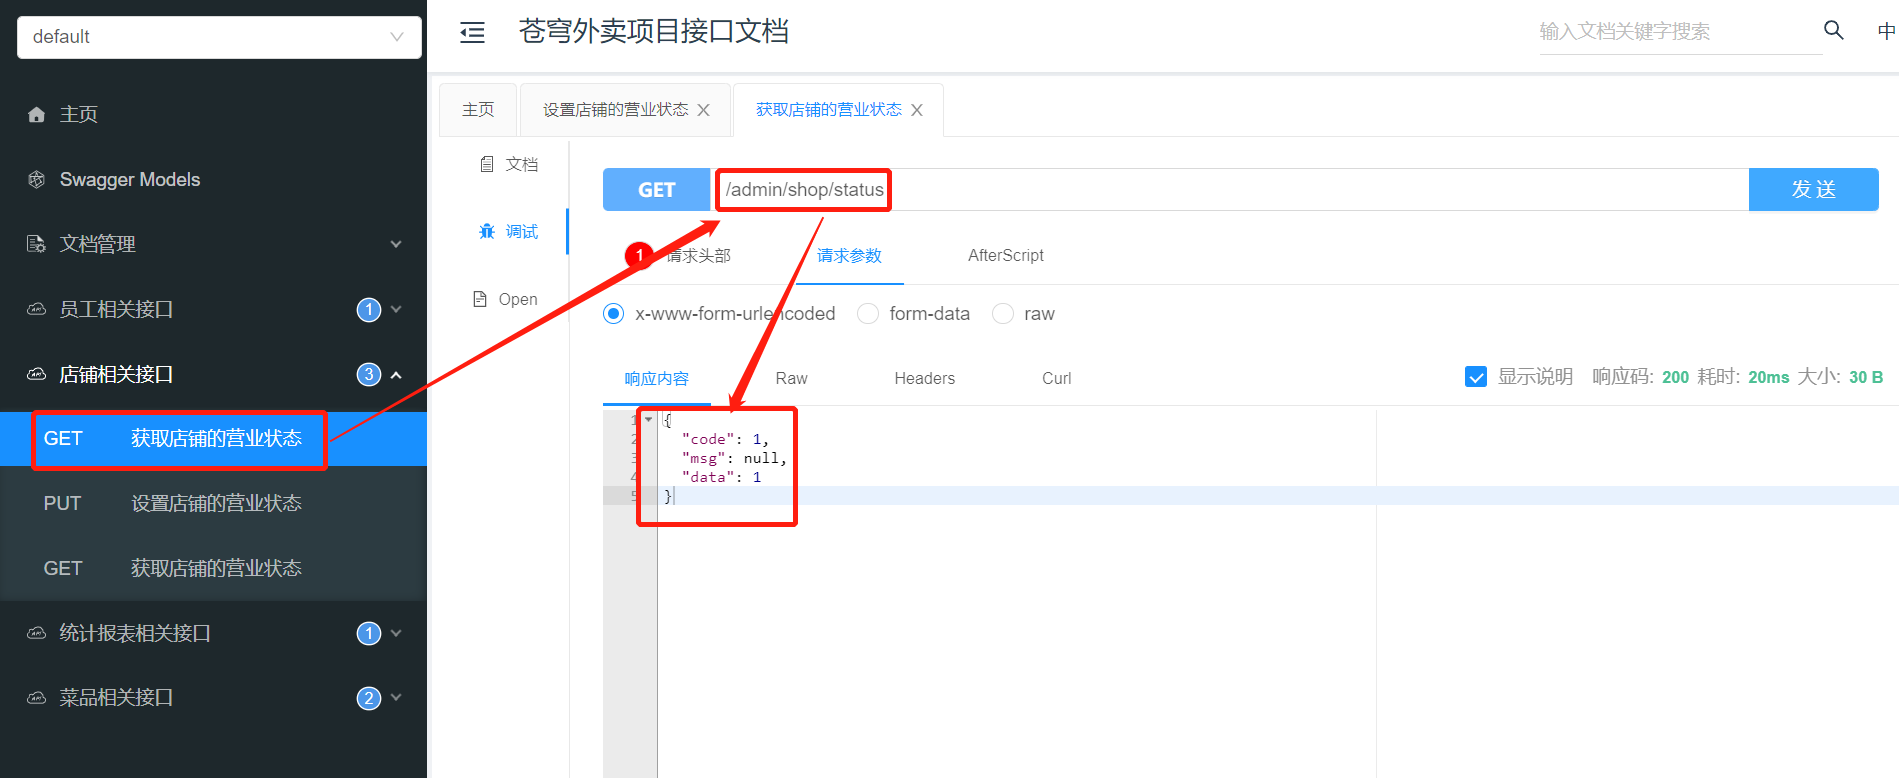 


**用户端查询营业状态：**

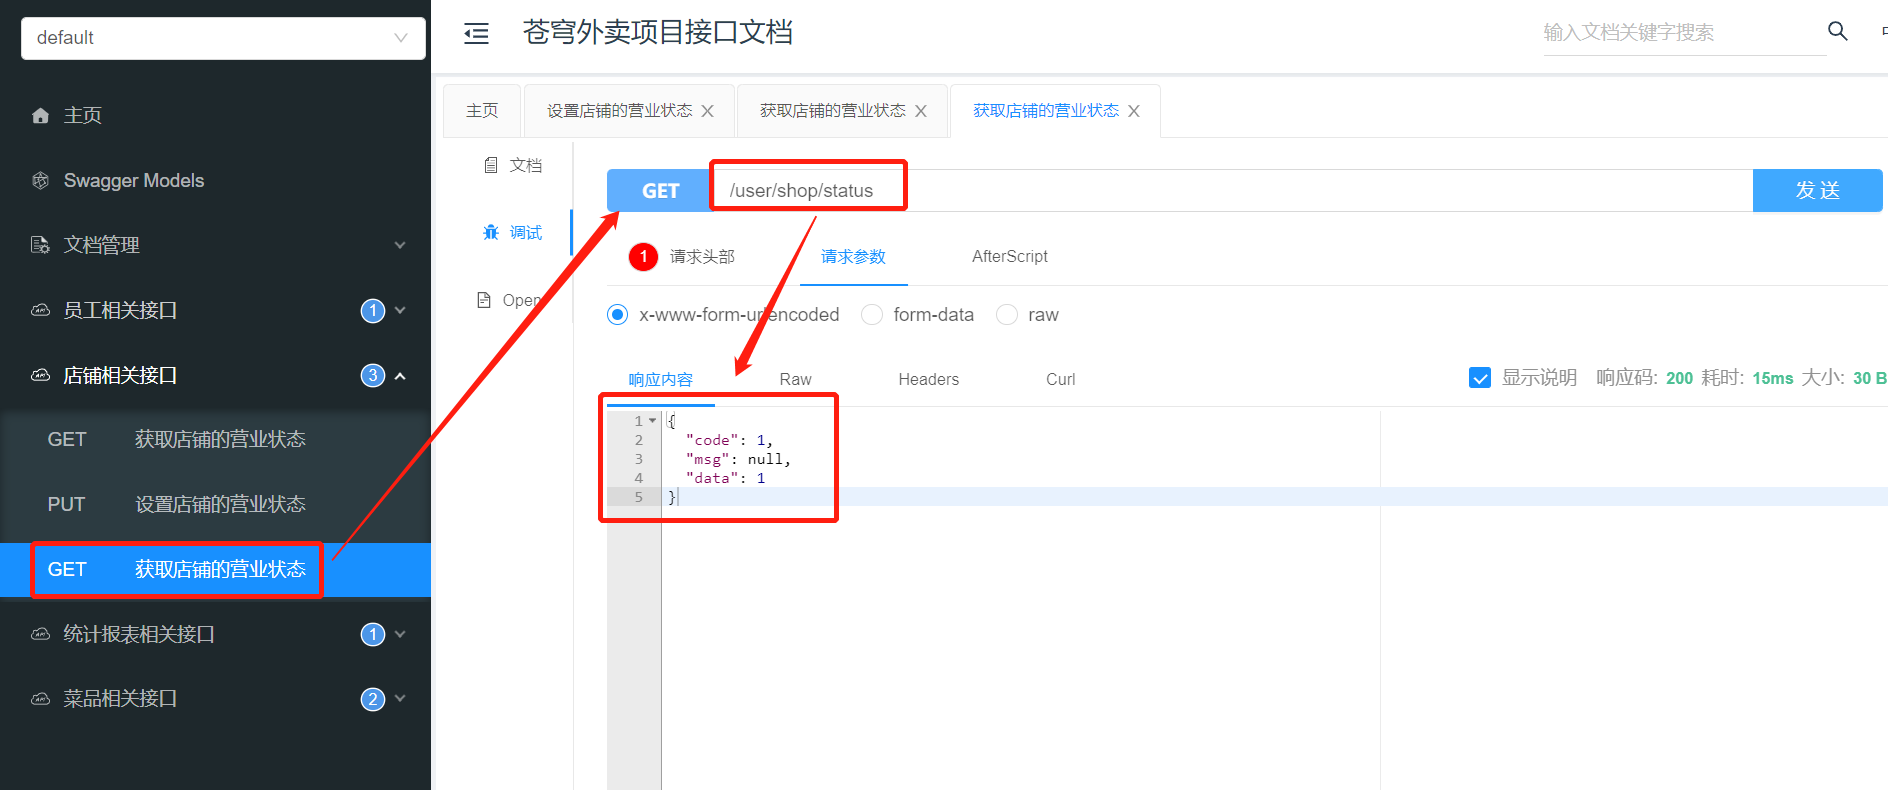 


#### 5.3.2 接口分组展示

在上述接口文档测试中，管理端和用户端的接口放在一起，不方便区分。

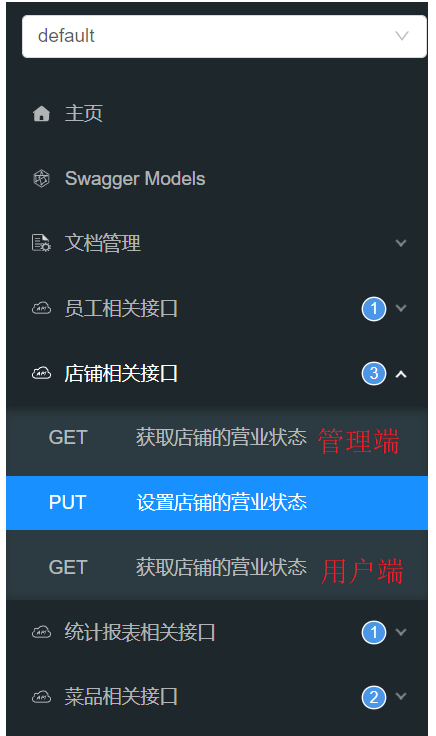 

接下来，我们要实现管理端和用户端接口进行区分。

在WebMvcConfiguration.java中，分别扫描"com.sky.controller.admin"和"com.sky.controller.user"这两个包。

```java
	@Bean
    public Docket docket1(){
        log.info("准备生成接口文档...");
        ApiInfo apiInfo = new ApiInfoBuilder()
                .title("苍穹外卖项目接口文档")
                .version("2.0")
                .description("苍穹外卖项目接口文档")
                .build();

        Docket docket = new Docket(DocumentationType.SWAGGER_2)
                .groupName("管理端接口")
                .apiInfo(apiInfo)
                .select()
                //指定生成接口需要扫描的包
                .apis(RequestHandlerSelectors.basePackage("com.sky.controller.admin"))
                .paths(PathSelectors.any())
                .build();

        return docket;
    }

    @Bean
    public Docket docket2(){
        log.info("准备生成接口文档...");
        ApiInfo apiInfo = new ApiInfoBuilder()
                .title("苍穹外卖项目接口文档")
                .version("2.0")
                .description("苍穹外卖项目接口文档")
                .build();

        Docket docket = new Docket(DocumentationType.SWAGGER_2)
                .groupName("用户端接口")
                .apiInfo(apiInfo)
                .select()
                //指定生成接口需要扫描的包
                .apis(RequestHandlerSelectors.basePackage("com.sky.controller.user"))
                .paths(PathSelectors.any())
                .build();

        return docket;
    }
```

重启服务器，再次访问接口文档，可进行选择**用户端接口**或者**管理端接口**

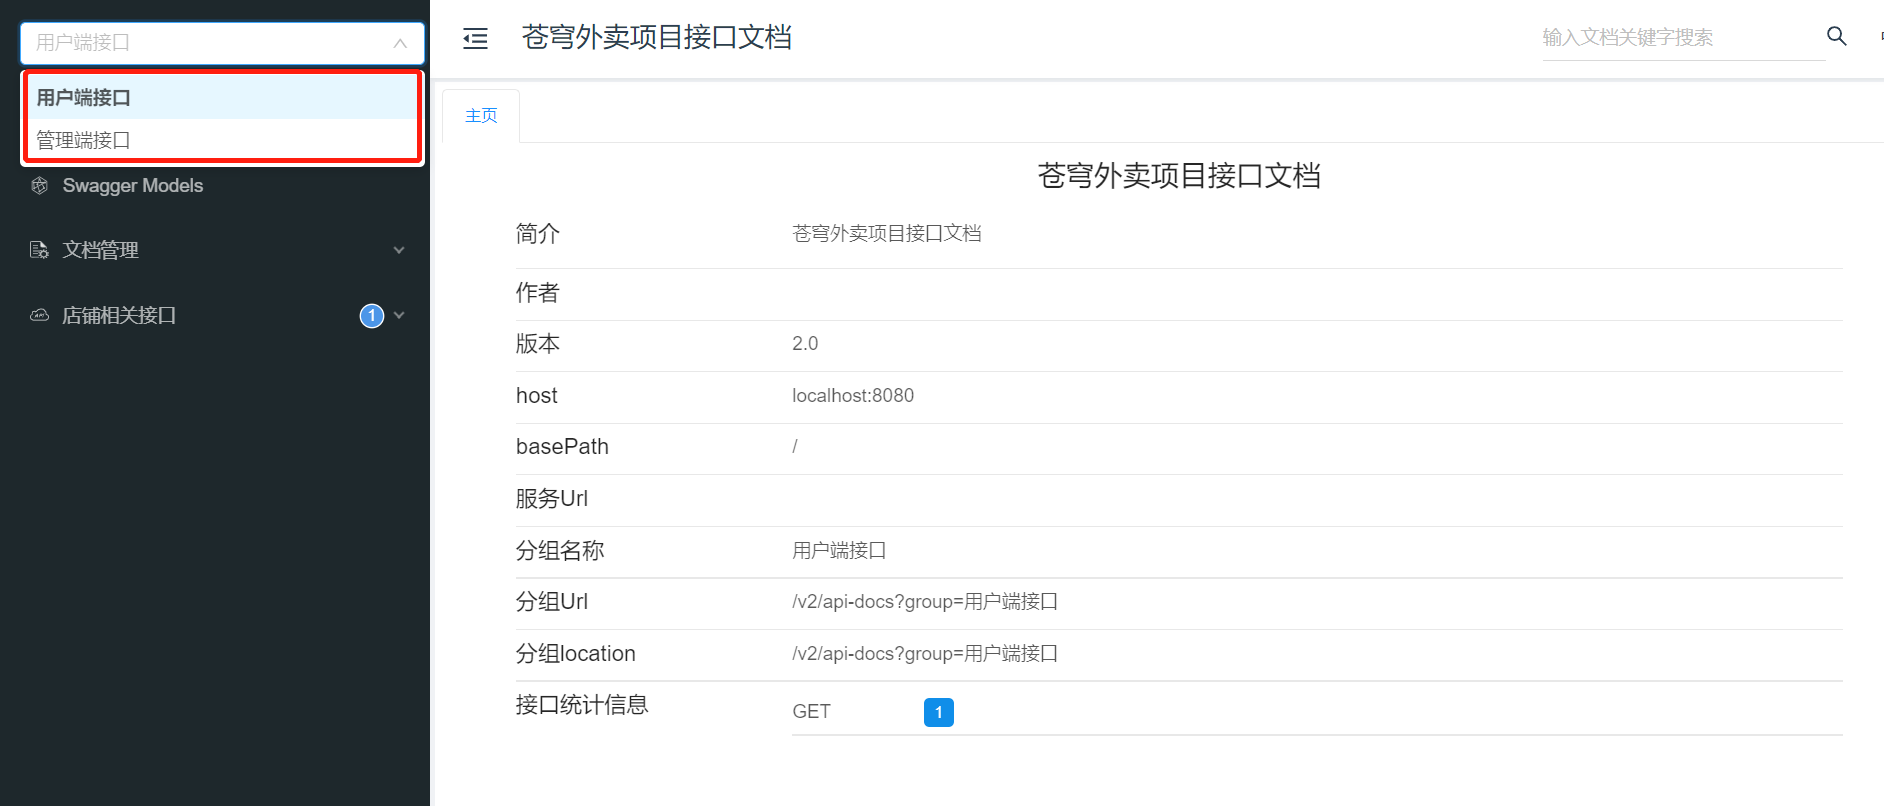 


#### 5.3.3 前后端联调测试

启动nginx,访问 http://localhost

进入后台，状态为**营业中**

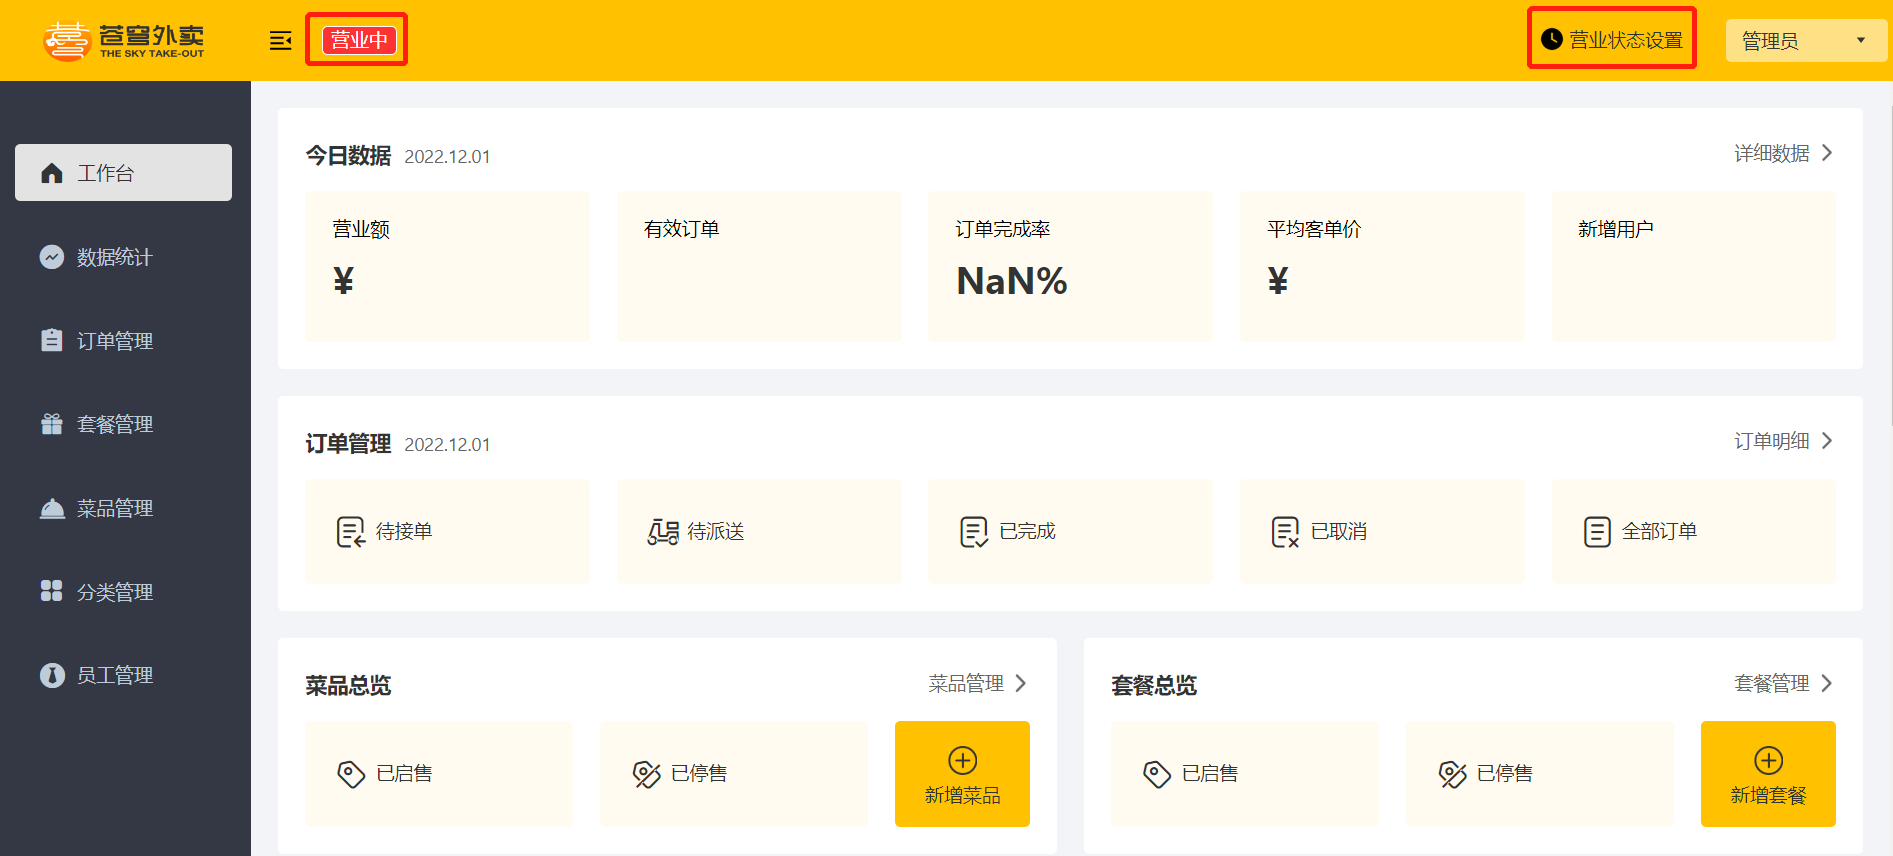 

点击**营业状态设置**，修改状态为**打烊中**

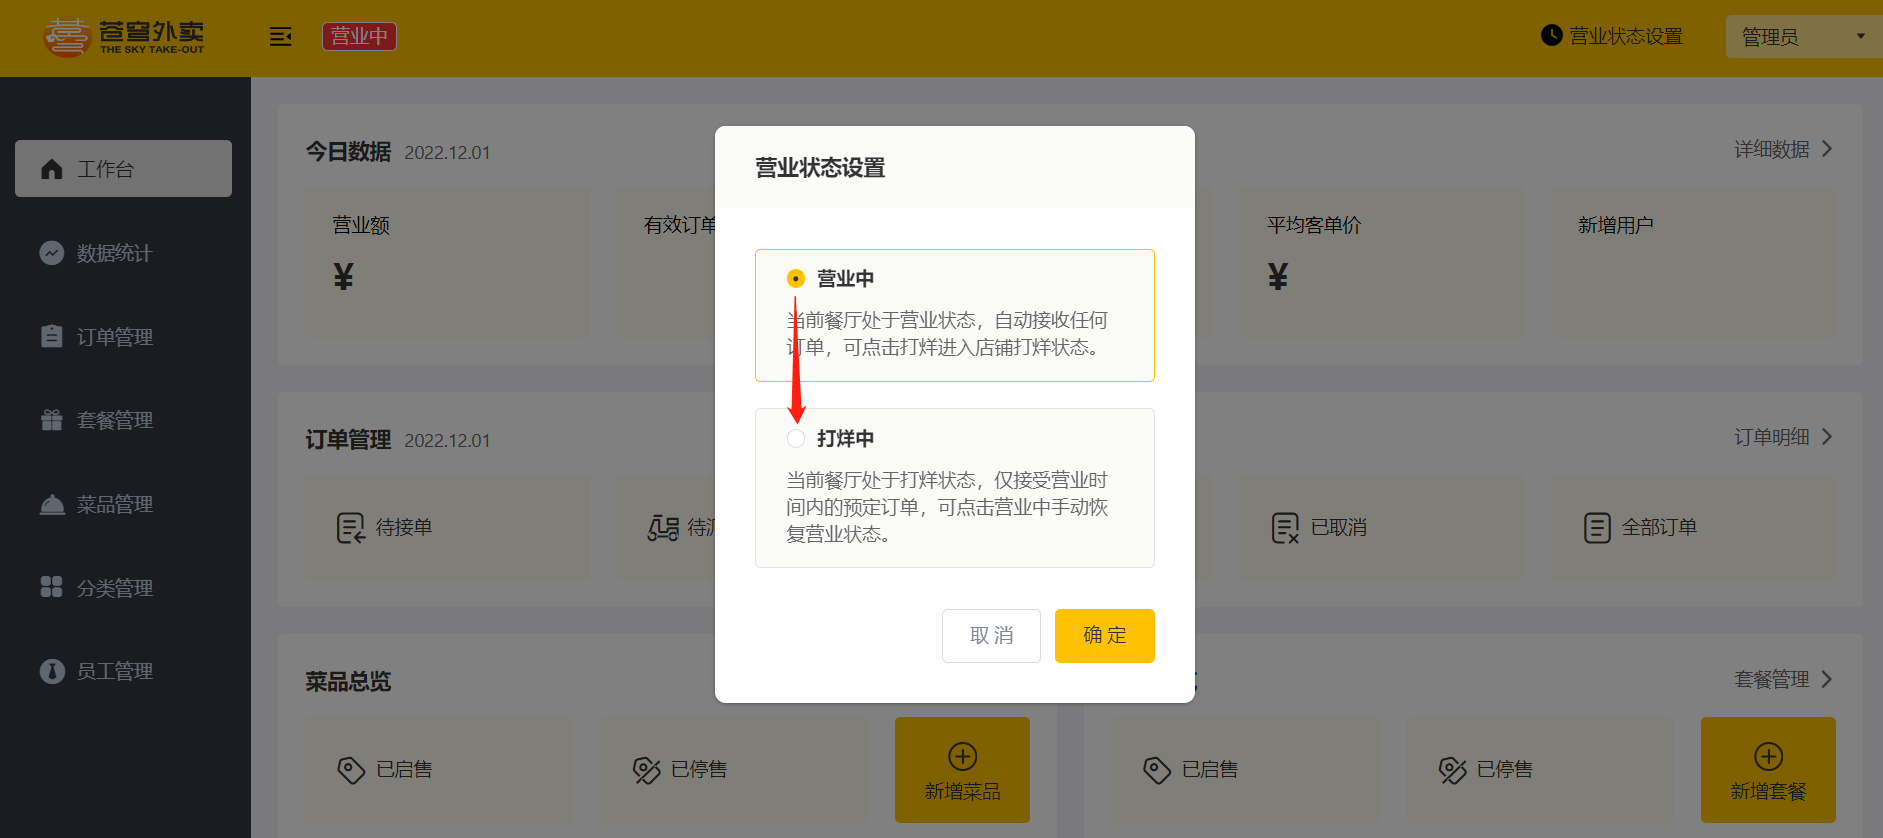 

再次查看状态，状态已为**打烊中**

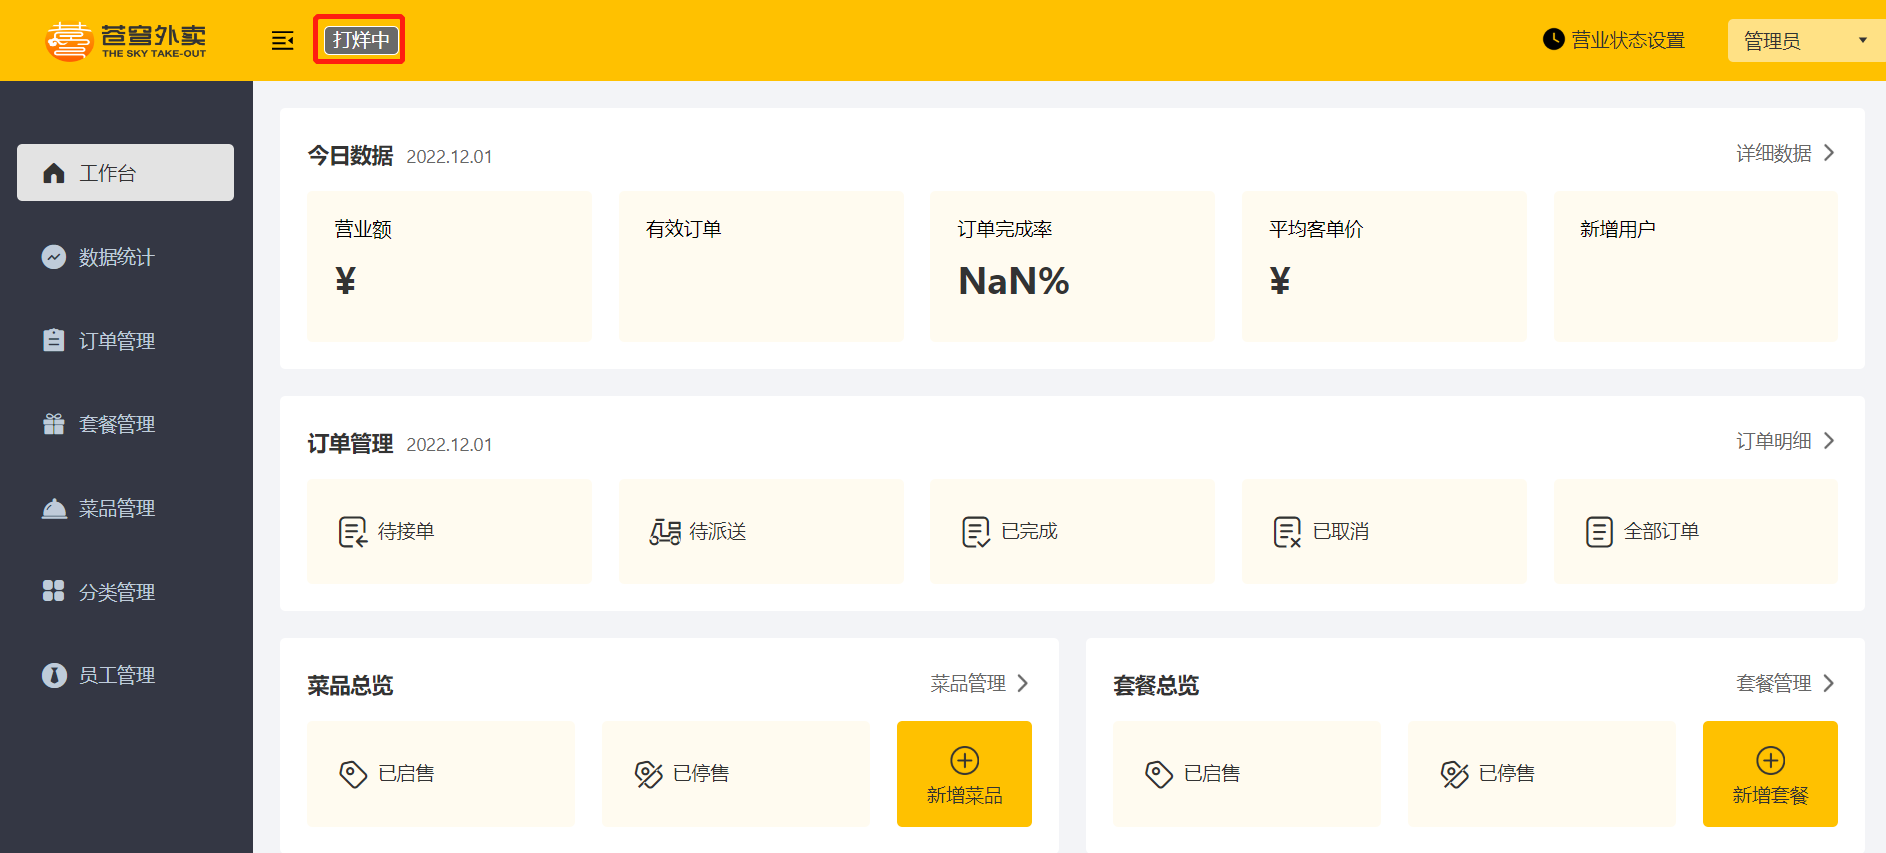


### 接口、Redis与页面一起验收（补充）

| 场景 | 预期检查 |
| --- | --- |
| PUT /admin/shop/1 | 成功；管理端与用户端data均为整数1 |
| PUT /admin/shop/0 | 成功；两端均为整数0，页面显示打烊 |
| PUT /admin/shop/2或负数 | 拒绝；原合法状态保持不变 |
| status传非数字 | 参数绑定报错，不进入正常写入 |
| key尚不存在 | 原代码会空指针；补充方案返回约定的0 |
| Redis中存在错误value格式 | 返回数据格式错误，定位序列化方案 |
| Redis连接中断 | 明确失败，不把错误当作成功设置 |
| 无权限修改状态 | 由管理端鉴权拒绝，不修改key |
| 刷新管理页面 | 重新查询后仍与当前Redis状态一致 |

在课程JDK方案下，通过Java写接口初始化和切换；Redis图形工具选db10，可以核对key、TYPE和TTL，但不要为了让GET显示文本随意覆盖它。接口返回Integer不等于底层Redis保存的是ASCII数字。

#### 接口分组只改变文档展示

原两个Docket分别扫描admin与user包，groupName显示“管理端接口”“用户端接口”。用它们替换原单组文档配置，避免仍保留覆盖全部Controller的旧Docket造成重复展示。

扫描包字符串必须与实际Java包一致。分组不会改变请求路径，也不等于用户端与管理端自动隔离权限。Docket、Swagger 2注解属于原工程的文档栈，升级到其他文档库时不能只复制这两个Bean。

文档里测试成功后，再通过Nginx联调页面；若文档正常而页面404，检查代理路径；若提示401，检查有效token和对应端的拦截器；若两个端读到不同值，优先检查Redis实例、数据库、key与部署环境。


### 5.4 代码提交

**点击提交：**

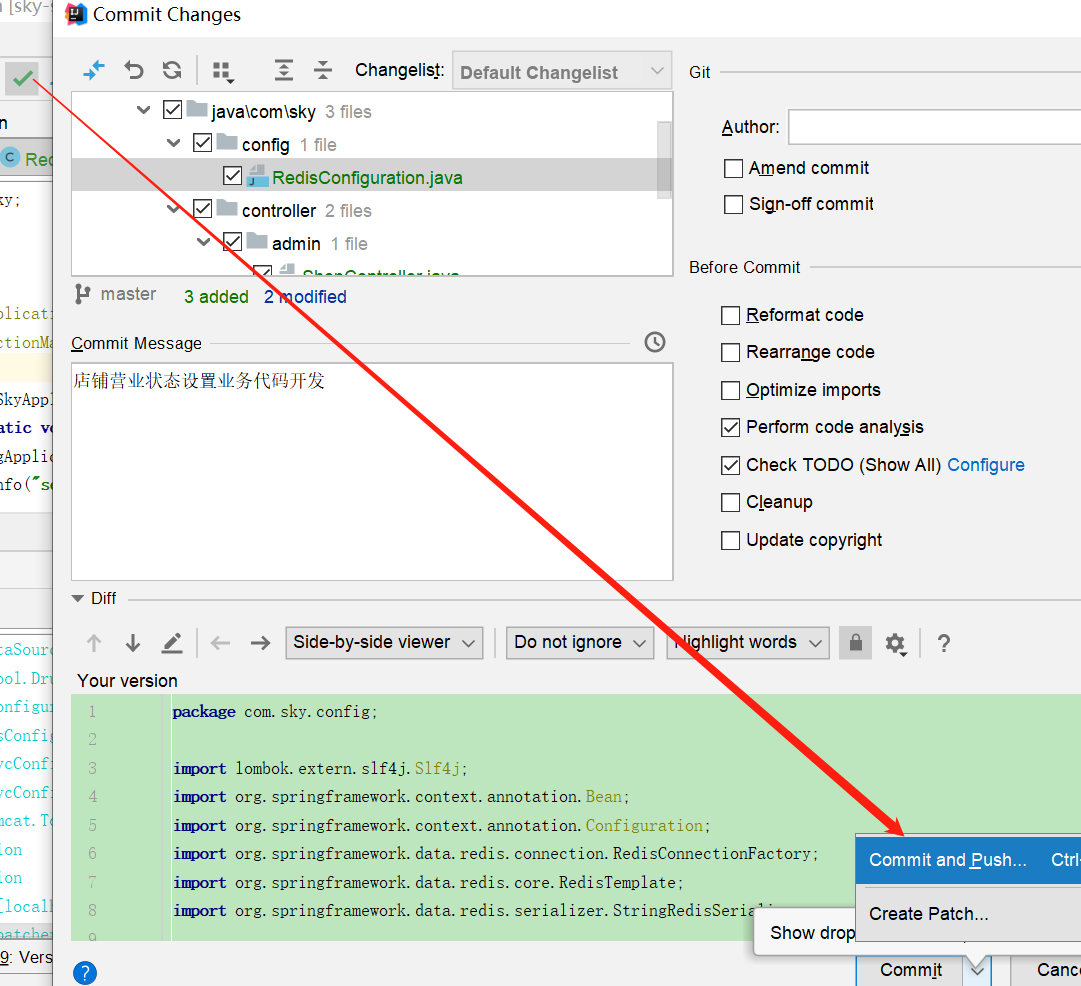 

**提交过程中**，出现提示：

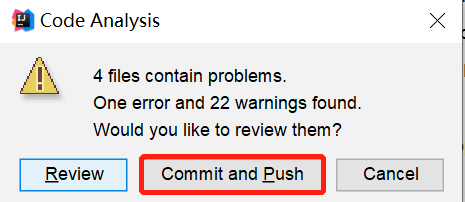  

**继续push:**

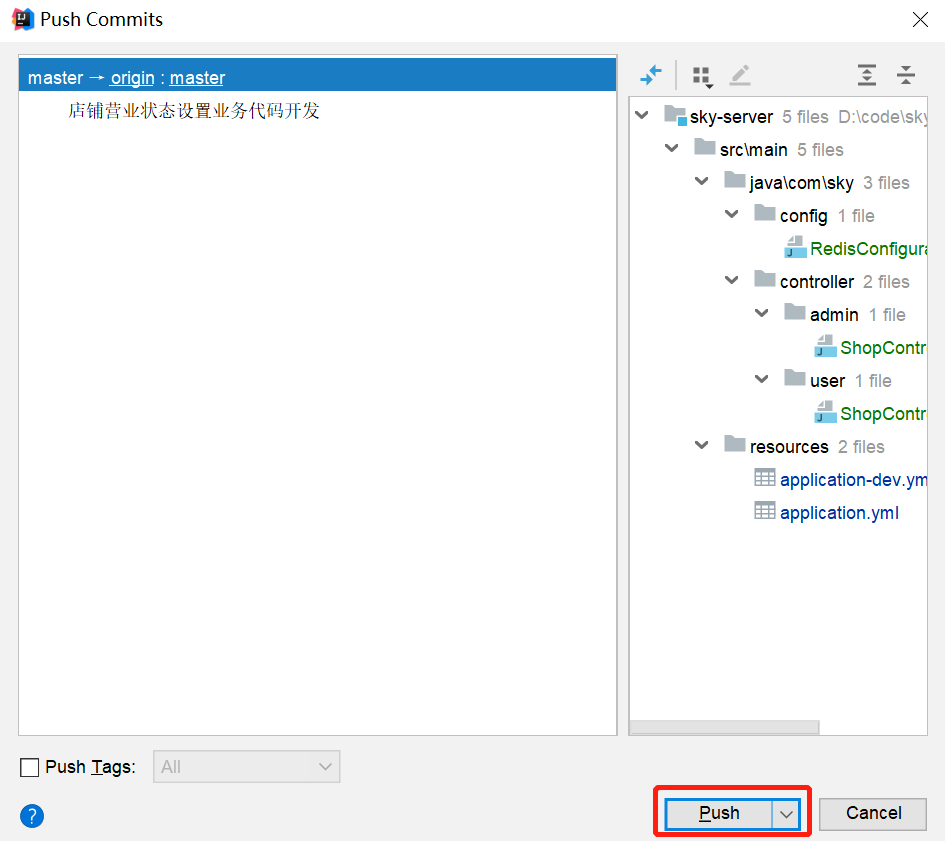 

**推送成功：**

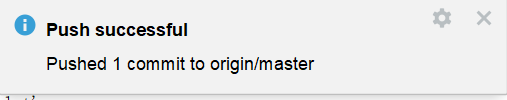


### 对照截图提交自己的业务代码（补充）

讲义保留了提交与push截图。实际跟练时先查看自己的改动，确认只包含Redis配置结构、模板与营业状态代码，以及必要的文档分组；真实密码通过本地配置或启动环境管理。

截图中的分支、远程地址和提示以老师的仓库为例，不直接套用到自己的仓库。本次仅生成笔记，未替你的业务工程执行提交或推送。


## 复习速查与本章验收（补充）

| 内容 | 核心记忆 |
| --- | --- |
| Redis | 基于内存的key-value数据库，支持多种结构与持久化 |
| 连接 | host、port、password、database四项要对齐 |
| 类型 | string单值、hash字段、list顺序、set去重、zset分数 |
| 列表顺序 | LPUSH a b c后是c,b,a；左右操作决定队列方向 |
| 过期时间 | TTL=-1无期限，-2不存在；SET可改变旧TTL |
| SETNX | key不存在才设置，不等于完整分布式锁 |
| 查找 | 少量练习可KEYS，大量key迭代用SCAN |
| RedisTemplate | operations按类型分类，连接与序列化是不同职责 |
| 课程序列化 | key可读，value默认JDK；不能混写纯文本1 |
| SHOP_STATUS | 同一数据库同一key，Integer 1营业、0打烊 |
| 两个Controller | Bean名称和路径都区分，共享业务状态 |
| 接口分组 | 文档展示规则，不提供鉴权 |

### 常见问题排查

| 表现 | 检查方向 |
| --- | --- |
| Connection refused | 服务是否运行、地址端口、部署网络 |
| NOAUTH或WRONGPASS | 实例是否启用认证、Java与客户端密码 |
| Redis界面找不到Java写入数据 | 是否看错db0/db10或另一实例 |
| key可读而value像乱码 | 默认JDK序列化，不是数据必然损坏 |
| invalid stream header | 命令行或其他客户端混写了不同字节格式 |
| ClassCastException | Integer/String类型与序列化约定不一致 |
| WRONGTYPE | key原类型和当前操作命令不匹配 |
| 列表输出反向 | LPUSH多参数按逐个左插理解 |
| Bean名称冲突 | 同名ShopController显式区分Bean名称 |
| GET状态空指针 | key不存在，status==1自动拆箱null |
| 非法状态也设置成功 | 写接口缺少0/1校验 |
| 文档重复或接口分组不对 | 旧Docket、扫描包与groupName |

### 跟练验收清单

- [ ] Redis能正确认证，客户端和Java连接相同实例与db10。
- [ ] 五种类型的写读命令都能解释返回结果，练习key有独立前缀。
- [ ] 理解过期、SETNX、集合顺序与zset分数的含义。
- [ ] Spring Data Redis通过真实命令完成连接验证。
- [ ] key、value、hash字段的序列化规则已明确，不混用两套格式。
- [ ] 课程示例测试的imports齐全，不依赖@Test执行顺序。
- [ ] 写接口只接受0或1，非法请求不覆盖已有合法状态。
- [ ] 两端查询同一状态，缺失key按明确定义处理。
- [ ] Redis故障或格式错误返回失败，不伪装成已成功设置。
- [ ] 管理端与用户端文档分组可切换，鉴权按实际配置生效。
- [ ] 页面切换、刷新结果与接口一致，确认后续下单还需服务端检查。

### 自测问题

1. 为什么关闭redis-cli不会停止redis-server？
2. Java在db10写入后，命令行db0看不到，说明什么？
3. Java Integer保存到Redis后，TYPE为什么仍是string？
4. 普通SET覆盖带TTL的key，期限可能怎样变化？
5. SETNX与一个可安全释放的分布式锁差在哪里？
6. LPUSH a b c后，从右边弹出的第一个元素是什么？
7. set与zset都去重，为什么zset还支持不同成员拥有同分数？
8. HKEYS、HVALS为什么不能按两次输出的索引配对？
9. 为什么只打印RedisTemplate不能证明Redis已连接成功？
10. 只设置key序列化后，value与hash field会怎样存储？
11. 为什么命令行SET SHOP_STATUS 1可能导致原Java查询失败？
12. 原getStatus在key不存在时，为什么连日志比较都会报错？
13. 默认打烊属于课程既定事实，还是需要明确选择的补充约定？
14. 接口文档分组、路径前缀和鉴权有什么不同？
15. 页面不允许点下单按钮，为什么服务端仍应检查营业状态？

后续用户端登录与商品浏览会继续读取营业状态；缓存菜品和套餐时，也会用到本章的连接配置、命名和序列化知识。
